# Task 12 — Seller lead scoring: which leads to call first, and whether they became sellers

**Study unit:** ARI3217 — AI Enterprise Architectures and Transformation (University of Malta)
**Dataset:** [Marketing Funnel by Olist](https://www.kaggle.com/datasets/olistbr/marketing-funnel-olist) (8,000 seller leads, 842 closed deals), joined on `seller_id` to the [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce)
**Task family:** tabular supervised learning on small data, bootstrap intervals, a capacity-based operating point, a CRM-to-marketplace knowledge graph · **Companion task:** `02_card_fraud_tabular.ipynb` (the same honest evaluation, with a sales queue for an alert queue)

---

## The task card

> **Board question.** *In spring 2018 about 300 seller leads a week reached the sales team in this sample, and the team can make about 60 discovery calls a week. Which 60 should it call, how many more deals does a ranked queue win than calling in arrival order, and how many of the sellers we close go on to sell?*

**Business context.** Olist connects small Brazilian merchants to the large marketplaces. A merchant fills in a landing-page form, a sales development rep qualifies the lead by phone, a sales rep closes the deal, and the new seller builds a catalogue and, with luck, sells. The score sits between the marketing-automation tool and the CRM as an *offline batch* that re-ranks the queue weekly (Session 01's batch-prediction pattern); a person decides whom to call (*human-in-the-loop*). Value appears months later in a third system, the marketplace.

**What you will build from this notebook (see *Student tasks* at the end):**

1. the given **lead score**, packaged and reproducible, evaluated *forward in time* with bootstrap intervals, with the traps guarded by tests;
2. an **operating point**: calls per week against deals, sellers and GMV, constants in an ADR;
3. the **operational wrapper**: package, CI gate on the *lower bound* of a frozen holdout, registry, model card, monitoring;
4. a **knowledge graph** from lead to seller to orders and reviews, with SHACL and the category-context ablation.

**Where this sits in the unit**

| Block | What this task exercises |
|---|---|
| 1 · EA for AI | Batch scoring between marketing tool, CRM and marketplace; GDPR and AI Act position |
| 2 · MLOps | Forward validation, bootstrap intervals, a lower-bound gate, two label clocks |
| 3 · Semantic layer | Lead → seller → order → review graph; a segment-to-category crosswalk; SHACL |
| 4 · LLM/RAG | A call-prep brief grounded in the lead's form and earlier sellers' outcomes |

**Assessment.** A *worked baseline plus tasks*; marks follow `docs/task-rubric.md`. The model is given: you are marked on how you package, evaluate, deploy, monitor and govern it, not on improving it. The notebook contains **deliberate traps**, each flagged with ⚠ in the text; turning each into a test is part of the task.

**Honesty note.** The data is **real**, anonymised and sampled by Olist (leads "randomly sampled from the total of MQLs"), so weekly volumes are a sample's. Nobody recorded which leads were called: we assume every lead was worked and that an uncalled lead does not close. The operating point inherits both untestable assumptions.

---

## How this notebook is organised

The notebook has three parts. Parts A and B are given; Part C is your assignment. **The model is given:** you package, evaluate, deploy and monitor it; you do not design, tune or replace it.

| Part | Sections | What it contains | What you do with it |
|---|---|---|---|
| **A · Explore the data** | 1–2 | Dataset card and first look at the funnel and its two clocks | Read. Its quirks go into your model card and data contract. |
| **B · The given model** | 3–5 | The lead score forward in time with intervals, the calls-per-week operating point, the traps | Read, then package the code unchanged and reproduce its numbers (C2). |
| **C · Productionise it** | 6–10 | The channel and conversion shift after deployment, the CRM-to-marketplace knowledge graph, the module spine, student tasks, hand-in checklist | Your work: package, test, gate, track, serve, monitor, govern. Section 6 shows the fall your monitoring must catch. |

**What you need from Parts A and B**

- **Code to package:** `get_raw`, `get_raw_market`, `load_funnel` and `load_marketplace` (Section 1); `wilson` (Section 2); `page_history`, `origin_rule`, `lr_design`, `fit_predict` and `boot_ap` (Section 3); `week_rank`, `top_mask` and `closed_at_capacity` (Section 4); `psi` and `page_bucket` for monitoring (Section 6); `build_kb` and `category_context` (Section 7).
- **Parameters for `config/config.yaml`:** the CAPITALS in Section 0.
- **Numbers your pipeline must reproduce (C2):** train 2,169 leads (257 closed), validation 1,174 (141) and test 2,655 (280, base rate 10.5 %); logistic regression chosen on March, test AUPRC 0.175 with a bootstrap lower bound of 0.154 against the gate's 0.15; at 60 calls a week, 11.8 closed deals a week (interval 10.1–13.5) against 6.3 unranked, worth 4.7 sellers and R$ 6,809 of 90-day GMV a week.
- **Runtime:** under a minute on a laptop (20 s on the build machine).

## 0 · Setup

*Before Part A · the parameters below move into `config/config.yaml`.*

In [1]:
%matplotlib inline
import os, json, time, hashlib, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import sklearn
import rdflib
import pyshacl
from rdflib import Graph, Literal, Namespace, RDF, XSD
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 20)

# ---- parameters -------------------------------------------------------------
SEED = 3217
N_JOBS = 1                                   # threads per model; raise it on your own laptop
KAGGLE_HANDLE = "olistbr/marketing-funnel-olist"         # CRM side: leads and closed deals
KAGGLE_HANDLE_MARKET = "olistbr/brazilian-ecommerce"     # marketplace side: order items, orders, reviews, products
WINDOW_START = pd.Timestamp("2018-01-01")    # modelling window; the closed-deal table is left-truncated before it (Trap 4)
TRAIN_END = pd.Timestamp("2018-03-01")       # train: leads first contacted Jan – Feb 2018
VALID_END = pd.Timestamp("2018-04-01")       # validation (model choice): March 2018; the chosen model is refitted on Jan – Mar
TEST_END = pd.Timestamp("2018-06-01")        # test, the frozen CI holdout: April – May 2018, the last two months of leads
CLOSE_HORIZON_DAYS = 90                      # label: the deal is won within 90 days of first contact
SELLER_HORIZON_DAYS = 90                     # "became a seller": at least one marketplace order within 90 days of the win
MARKET_END = pd.Timestamp("2018-09-01")      # the order data effectively stops at the end of August 2018
CALLS_PER_WEEK = 60                          # discovery calls the sales team can make in a week (assumption — task C3)
GATE_MIN_AUPRC = 0.15                        # bar for the LOWER bound of test AUPRC: illustrative, not derived (assumption — task C3)
CALIBRATION_BAND = (0.8, 1.25)               # expected ÷ realised closes per contact month; outside = retrain (assumption — task C3)
PRIOR_LEADS = 20                             # smoothing weight for a landing page's win rate (pseudo-leads at the base rate)
N_BOOT = 1000                                # bootstrap resamples behind every interval
CI = (5, 95)                                 # percentiles: 90 % intervals

DATA_DIR = Path(os.environ.get("DATASETS_TASKS_DATA", Path.cwd().parent.parent / "data"))
RAW, PROCESSED = DATA_DIR / "raw" / "olist_funnel", DATA_DIR / "processed"
RAW_MARKET = DATA_DIR / "raw" / "olist"      # shared with task 11
RAW.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "legend.frameon": False, "figure.dpi": 110,
})
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
T_START = time.time()
print(f"pandas {pd.__version__} · lightgbm {lgb.__version__} · scikit-learn {sklearn.__version__} · "
      f"numpy {np.__version__} · rdflib {rdflib.__version__} · pyshacl {pyshacl.__version__}")

pandas 3.1.0 · lightgbm 4.7.0 · scikit-learn 1.9.1 · numpy 2.5.4 · rdflib 7.6.0 · pyshacl 0.40.1


# Part A — Explore the data

*Sections 1–2: read them; the quirks they find go into your model card and data contract.*

## 1 · Dataset card

*Part A · Explore · read; package `get_raw`, `get_raw_market`, `load_funnel` and `load_marketplace`; employee ids are dropped there.*

| Field | Value |
|---|---|
| **Source** | Kaggle `olistbr/marketing-funnel-olist` and `olistbr/brazilian-ecommerce` (Olist, 2018) |
| **Licence** | CC BY-NC-SA 4.0 for both: attribution, non-commercial use, share alike |
| **Provenance** | Real CRM and marketplace extracts, hashed identifiers; leads randomly sampled from all marketing-qualified leads (MQLs) of Jun 2017 – Jun 2018 |
| **Size** | 8,000 leads (first contact 14 Jun 2017 – 31 May 2018); 842 closed deals (won 5 Dec 2017 – 14 Nov 2018); 112,650 order items from 3,095 sellers (Sep 2016 – Sep 2018) |
| **Files** | `olist_marketing_qualified_leads_dataset.csv`, `olist_closed_deals_dataset.csv`; `olist_order_items_dataset.csv`, `olist_orders_dataset.csv`, `olist_order_reviews_dataset.csv`, `olist_products_dataset.csv` |
| **Schema** | Lead: `first_contact_date`, `landing_page_id` (495 pages), `origin`. Deal: `seller_id`, `sdr_id`, `sr_id`, `won_date`, nine fields filled in by sales. Marketplace: price, seller, purchase time, category, review score |
| **Label** | `closed`: won within 90 days of first contact (11.3 % of Jan – May 2018 leads). Downstream: sold within 90 days of the win (43 % of the 667 deals old enough to judge) |
| **Window used here** | Model on Jan – May 2018 (5,998 leads): train Jan – Feb, validate March, test April – May (the frozen CI holdout) |
| **PII** | `sdr_id` and `sr_id` identify employees: dropped on load. Customers' review text: never loaded. Sole traders' data can be personal data (GDPR Art. 4(1)) |

**Known quirks you must handle (and should mention in your model card):**

1. ⚠ **Post-call fields.** The nine deal fields are filled for 99.3 % of closed leads and no other: their presence *is* the label (Trap 1).
2. ⚠ **The deal table starts on 5 December 2017.** Jul – Nov 2017 leads converted at 2.8 % (ever) against 13.9 % in Jan – Apr 2018. Earlier wins were left out or selling began then; the data cannot say which (Trap 4).
3. **Skewed time to close:** median 14 days, 90th percentile 162; a 90-day horizon keeps 86.4 % of 2018 wins.
4. **Orders stop at the end of August 2018** (one follows in September), so "sold within 90 days of the win" is known only for deals won by 3 June 2018 (667 of 842). Task 11 found the extract thins after June 2018 (later orders appear only once delivered; 44 a day in late August). No matured deal's first sale falls after 10 August, so these outcomes stand; July's thinning could only undercount "sold".
5. ⚠ **Closed is not selling.** 322 of the 667 matured deals (48 %) have no uncancelled order in the extract (463 of all 842, but 50 of those were won after the last order). Whether the 100k orders are all orders or a sample is not stated.
6. **Pages churn, origins mislead:** 247 of 495 pages have one lead while two carry 22 % of leads; 60 leads lack an origin and 1,099 say `unknown`, and both groups convert best.
7. **Self-declared numbers:** declared monthly revenue is 0 for 95 % of deals (maximum 50,000,000); catalogue size is 92 % missing.

In [2]:
POST_CALL = ["business_segment", "lead_type", "lead_behaviour_profile", "has_company", "has_gtin", "average_stock",
             "business_type", "declared_product_catalog_size", "declared_monthly_revenue"]   # filled in by sales, after the call

def get_raw(filename: str) -> Path:
    local = RAW / filename
    if local.exists():
        return local
    import kagglehub
    return Path(kagglehub.dataset_download(KAGGLE_HANDLE, path=filename))

def get_raw_market(filename: str) -> Path:
    local = RAW_MARKET / filename
    if local.exists():
        return local
    import kagglehub
    return Path(kagglehub.dataset_download(KAGGLE_HANDLE_MARKET, path=filename))

def load_funnel() -> pd.DataFrame:
    """One row per marketing-qualified lead, with its closed deal (if any) joined on."""
    cache = PROCESSED / "12_leads.parquet"
    if cache.exists():
        return pd.read_parquet(cache)
    t = time.time()
    mql = pd.read_csv(get_raw("olist_marketing_qualified_leads_dataset.csv"), parse_dates=["first_contact_date"])
    deals = pd.read_csv(get_raw("olist_closed_deals_dataset.csv"), parse_dates=["won_date"])
    # ---- governance on load: sdr_id / sr_id identify individual employees (and exist only after the call) ----
    deals = deals.drop(columns=["sdr_id", "sr_id"])
    df = mql.merge(deals, on="mql_id", how="left", validate="one_to_one")
    df["origin"] = df.origin.fillna("(missing)")
    df = df.sort_values(["first_contact_date", "mql_id"], kind="stable").reset_index(drop=True)
    df.to_parquet(cache)
    print(f"loaded + cached in {time.time()-t:.1f}s")
    return df

def load_marketplace() -> pd.DataFrame:
    """One row per order item on the whole marketplace: seller, price, purchase time, category, review score."""
    cache = PROCESSED / "12_marketplace_items.parquet"
    if cache.exists():
        return pd.read_parquet(cache)
    t = time.time()
    items = pd.read_csv(get_raw_market("olist_order_items_dataset.csv"), usecols=["order_id", "product_id", "seller_id", "price"])
    orders = pd.read_csv(get_raw_market("olist_orders_dataset.csv"), usecols=["order_id", "order_status", "order_purchase_timestamp"],
                         parse_dates=["order_purchase_timestamp"])
    # review TEXT is written by customers: never loaded. Only the score and its date.
    reviews = pd.read_csv(get_raw_market("olist_order_reviews_dataset.csv"), usecols=["order_id", "review_score", "review_creation_date"],
                          parse_dates=["review_creation_date"])
    reviews = reviews.groupby("order_id").agg(review_score=("review_score", "mean"), review_date=("review_creation_date", "min"))
    products = pd.read_csv(get_raw_market("olist_products_dataset.csv"), usecols=["product_id", "product_category_name"])
    df = (items.merge(orders, on="order_id", how="inner").merge(products, on="product_id", how="left")
               .join(reviews, on="order_id").drop(columns=["product_id"])
               .rename(columns={"order_purchase_timestamp": "purchased", "product_category_name": "category"}))
    df = df.sort_values("purchased", kind="stable").reset_index(drop=True)
    df.to_parquet(cache)
    print(f"loaded + cached in {time.time()-t:.1f}s")
    return df

leads = load_funnel()
items = load_marketplace()
print(f"{len(leads):,} leads ({leads.first_contact_date.min():%d %b %Y} – {leads.first_contact_date.max():%d %b %Y}) · "
      f"{leads.seller_id.notna().sum():,} closed deals (won {leads.won_date.min():%d %b %Y} – {leads.won_date.max():%d %b %Y}) · "
      f"{len(items):,} marketplace order items from {items.seller_id.nunique():,} sellers "
      f"({items.purchased.min():%b %Y} – {items.purchased.max():%b %Y})")
leads.head(3)

8,000 leads (14 Jun 2017 – 31 May 2018) · 842 closed deals (won 05 Dec 2017 – 14 Nov 2018) · 112,650 marketplace order items from 3,095 sellers (Sep 2016 – Sep 2018)


,mql_id,first_contact_date,landing_page_id,origin,seller_id,won_date,business_segment,lead_type,lead_behaviour_profile,has_company,has_gtin,average_stock,business_type,declared_product_catalog_size,declared_monthly_revenue
0,0b99dab71519032b917dc641cdd7ac5b,2017-06-14,d41d8cd98f00b204e9800998ecf8427e,(missing),NaN,NaT,NaN,NaN,NaN,None,None,NaN,NaN,NaN,NaN
1,6dd0ef38856fd5fb21aed5223aea9e66,2017-06-14,8f08d2ef8b9aec2ec5118fbcf7f96f11,display,NaN,NaT,NaN,NaN,NaN,None,None,NaN,NaN,NaN,NaN
2,70bd89abdbdba90e471cd3d0bbdbac49,2017-06-16,8f08d2ef8b9aec2ec5118fbcf7f96f11,unknown,NaN,NaT,NaN,NaN,NaN,None,None,NaN,NaN,NaN,NaN


In [3]:
# The quirks in the dataset card, counted here
L = leads
dtc = (L.won_date - L.first_contact_date).dt.days
won = L.seller_id.notna()
month = L.first_contact_date.dt.to_period("M")
late17 = (L.first_contact_date < "2017-12-01")
print(f"closed-deal fields filled: {L.loc[won, 'lead_type'].notna().mean():.1%} of closed leads, "
      f"{L.loc[~won, POST_CALL].notna().any(axis=1).mean():.1%} of the other {(~won).sum():,}")
print(f"conversion by first-contact month: Jul–Nov 2017 {won[late17].mean():.1%} · Jan–Apr 2018 "
      f"{won[(L.first_contact_date >= '2018-01-01') & (L.first_contact_date < '2018-05-01')].mean():.1%}; "
      f"median days to close for 2017 leads {dtc[late17 & won].median():.0f}, for 2018 leads {dtc[~late17 & won].median():.0f}")
print(f"days from first contact to win: median {dtc.median():.0f}, 90th pct {dtc.quantile(0.9):.0f}; "
      f"share of 2018 wins within {CLOSE_HORIZON_DAYS} days {(dtc[~late17 & won] <= CLOSE_HORIZON_DAYS).mean():.1%}; "
      f"won before first contact: {(dtc < 0).sum()}")
pages = L.groupby("landing_page_id").size()
print(f"landing pages: {len(pages)} · {(pages == 1).sum()} with a single lead · top 2 pages carry {pages.nlargest(2).sum() / len(L):.0%} of leads")
print(f"origin: {(L.origin == '(missing)').sum()} missing, {(L.origin == 'unknown').sum():,} 'unknown'")
print(f"declared_monthly_revenue = 0 for {(L.loc[won, 'declared_monthly_revenue'] == 0).mean():.0%} of deals, max {L.declared_monthly_revenue.max():,.0f}; "
      f"catalogue size missing for {L.loc[won, 'declared_product_catalog_size'].isna().mean():.0%}")
om = items.drop_duplicates("order_id").purchased.dt.to_period("M").value_counts().sort_index().tail(5)
print("marketplace orders by month: " + " · ".join(f"{k:%b %Y} {v:,}" for k, v in om.items()))
sold_ever = L.loc[won, "seller_id"].isin(set(items.loc[~items.order_status.isin(["canceled", "unavailable"]), "seller_id"]))
print(f"closed sellers with at least one order that was not cancelled: {sold_ever.sum()} of {won.sum()} ({sold_ever.mean():.0%})")

closed-deal fields filled: 99.3% of closed leads, 0.0% of the other 7,158
conversion by first-contact month: Jul–Nov 2017 2.8% · Jan–Apr 2018 13.9%; median days to close for 2017 leads 242, for 2018 leads 13


days from first contact to win: median 14, 90th pct 162; share of 2018 wins within 90 days 86.4%; won before first contact: 1
landing pages: 495 · 247 with a single lead · top 2 pages carry 22% of leads
origin: 60 missing, 1,099 'unknown'
declared_monthly_revenue = 0 for 95% of deals, max 50,000,000; catalogue size missing for 92%
marketplace orders by month: May 2018 6,853 · Jun 2018 6,160 · Jul 2018 6,273 · Aug 2018 6,452 · Sep 2018 1


closed sellers with at least one order that was not cancelled: 379 of 842 (45%)


## 2 · First look

*Part A · Explore · read; closed is not selling, which your model card must say.*

What a sales lead asks first: how many leads, from where, how many close, and what happens after the close. That takes two joins and two clocks: closing takes days to weeks, selling weeks to months, so every outcome is measured at a fixed horizon that has passed before the data ends.

In [4]:
# ---- the outcomes: closed within the horizon, and "became a seller" on the marketplace ----
VALID_ORDER = ~items.order_status.isin(["canceled", "unavailable"])
mk = items[VALID_ORDER & items.seller_id.isin(set(L.seller_id.dropna()))]
d = L.loc[won, ["mql_id", "seller_id", "won_date"]].merge(mk, on="seller_id")
d = d[(d.purchased >= d.won_date) & (d.purchased < d.won_date + pd.Timedelta(days=SELLER_HORIZON_DAYS))]
seller_out = d.groupby("mql_id").agg(orders_h=("order_id", "nunique"), gmv_h=("price", "sum"),
                                     review_h=("review_score", "mean"), first_sale=("purchased", "min"))
L = L.join(seller_out, on="mql_id")
L[["orders_h", "gmv_h"]] = L[["orders_h", "gmv_h"]].fillna(0)
L["closed"] = (dtc <= CLOSE_HORIZON_DAYS).astype(int)             # the label the lead score learns
L["seller_matured"] = won & (L.won_date + pd.Timedelta(days=SELLER_HORIZON_DAYS) <= MARKET_END)
L["active"] = (L.orders_h > 0).astype(int)                         # sold within the horizon after the win
L["good"] = ((L.active == 1) & (L.review_h >= 4)).astype(int)      # ... and its customers rated it 4 or 5 on average
L["month"] = month

deals = L[won]
mat = deals[deals.seller_matured]
funnel = pd.Series({
    "leads (Jun 2017 – May 2018)": len(L),
    "closed deals (ever)": int(won.sum()),
    "closed deals with a matured seller outcome": len(mat),
    f"… sold within {SELLER_HORIZON_DAYS} days of the win": int(mat.active.sum()),
    "… and average review ≥ 4": int(mat.good.sum()),
    "closed sellers never seen selling in the extract": int((~sold_ever).sum()),
    "… of which won after the last order (from 1 Sep 2018)": int((L.loc[won, "won_date"][~sold_ever.values] >= MARKET_END).sum()),
    "… of which matured deals": int((~mat.seller_id.isin(set(L.loc[won, "seller_id"][sold_ever.values]))).sum()),
})
display(funnel.to_frame("count"))
print(f"of matured deals: {mat.active.mean():.0%} sold within {SELLER_HORIZON_DAYS} days; 90-day GMV per closed deal "
      f"R$ {mat.gmv_h.mean():,.0f} (median among sellers that sold R$ {mat.loc[mat.active == 1, 'gmv_h'].median():,.0f}; "
      f"top 10 % of deals carry {mat.gmv_h.nlargest(int(len(mat) * 0.1)).sum() / mat.gmv_h.sum():.0%} of GMV); "
      f"judgeable = won by {MARKET_END - pd.Timedelta(days=SELLER_HORIZON_DAYS):%d %b %Y}; never seen selling: "
      f"{funnel.iloc[-1] / len(mat):.0%} of matured deals")
# the extract thins after June 2018 (task 11: later orders appear only once delivered). Does it touch the matured outcomes?
od = items.drop_duplicates("order_id").set_index("purchased").sort_index()
daily = {lab: len(od.loc[a:b]) / ((pd.Timestamp(b) - pd.Timestamp(a)).days + 1) for lab, a, b in
         [("May–Jun", "2018-05-01", "2018-06-30 23:59"), ("1–10 Aug", "2018-08-01", "2018-08-10 23:59"),
          ("11–23 Aug", "2018-08-11", "2018-08-23 23:59"), ("24–31 Aug", "2018-08-24", "2018-08-31 23:59")]}
THIN = pd.Timestamp("2018-08-11")
print("orders a day: " + " · ".join(f"{k} {v:.0f}" for k, v in daily.items()) + f" · matured deals whose 90-day window runs past "
      f"{THIN - pd.Timedelta(days=1):%d %b}: {(mat.won_date + pd.Timedelta(days=SELLER_HORIZON_DAYS) > THIN).sum()}, of which first sale "
      f"after it: {(mat.first_sale >= THIN).sum()} · share of their 90-day GMV dated after it: "
      f"{d.loc[d.mql_id.isin(mat.mql_id) & (d.purchased >= THIN), 'price'].sum() / d.loc[d.mql_id.isin(mat.mql_id), 'price'].sum():.1%}")

,count
leads (Jun 2017 – May 2018),8000
closed deals (ever),842
closed deals with a matured seller outcome,667
… sold within 90 days of the win,289
… and average review ≥ 4,225
closed sellers never seen selling in the extract,463
… of which won after the last order (from 1 Sep 2018),50
… of which matured deals,322


of matured deals: 43% sold within 90 days; 90-day GMV per closed deal R$ 510 (median among sellers that sold R$ 324; top 10 % of deals carry 81% of GMV); judgeable = won by 03 Jun 2018; never seen selling: 48% of matured deals
orders a day: May–Jun 213 · 1–10 Aug 303 · 11–23 Aug 236 · 24–31 Aug 44 · matured deals whose 90-day window runs past 10 Aug: 78, of which first sale after it: 0 · share of their 90-day GMV dated after it: 0.8%


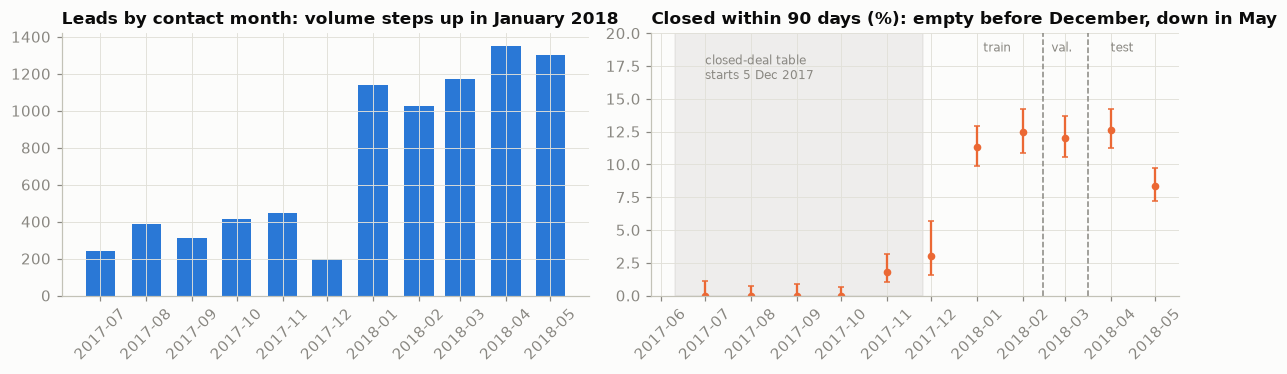

In [5]:
def wilson(k, n, z=1.645):
    p = k / n
    c = (p + z * z / (2 * n)) / (1 + z * z / n); h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return c - h, c + h

mon = L.groupby("month").agg(leads=("mql_id", "size"), closed=("closed", "sum"))
mon = mon[mon.leads >= 50]                                          # June 2017 has 4 leads
mon["rate"] = mon.closed / mon.leads
mon["lo"], mon["hi"] = wilson(mon.closed, mon.leads)
t_ = mon.index.to_timestamp()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
ax = axes[0]
ax.bar(t_, mon.leads, width=20, color=SERIES[0])
ax.set_title("Leads by contact month: volume steps up in January 2018"); ax.tick_params(axis="x", rotation=45)
ax = axes[1]
ax.errorbar(t_, mon.rate * 100, yerr=[(mon.rate - mon.lo) * 100, (mon.hi - mon.rate) * 100], fmt="o", color=SERIES[1], ms=4, capsize=2)
ax.axvspan(t_.min() - pd.Timedelta(days=20), pd.Timestamp("2017-11-25"), color=MUTED, alpha=0.12)
ax.text(pd.Timestamp("2017-07-01"), 16.5, "closed-deal table\nstarts 5 Dec 2017", color=MUTED, fontsize=8)
for x in [TRAIN_END, VALID_END]:
    ax.axvline(x - pd.Timedelta(days=15), color=MUTED, ls="--", lw=1)
for x, lab_ in [("2018-01-05", "train"), ("2018-02-20", "val."), ("2018-04-01", "test")]:
    ax.text(pd.Timestamp(x), 18.6, lab_, color=MUTED, fontsize=8)
ax.set_ylim(0, 20)
ax.set_title(f"Closed within {CLOSE_HORIZON_DAYS} days (%): empty before December, down in May"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout()

In [6]:
w18 = L[(L.first_contact_date >= WINDOW_START) & (L.first_contact_date < TEST_END)]
by_origin = w18.groupby("origin").agg(leads=("mql_id", "size"), closed=("closed", "sum"))
by_origin["rate"] = by_origin.closed / by_origin.leads
by_origin["90 % interval"] = [f"{a:.1%} – {b:.1%}" for a, b in zip(*wilson(by_origin.closed, by_origin.leads))]
by_origin = by_origin.sort_values("leads", ascending=False)
weeks18 = (TEST_END - WINDOW_START).days / 7
print(f"Jan – May 2018: {len(w18):,} leads ({len(w18)/weeks18:.0f} a week), {w18.closed.sum()} closed within {CLOSE_HORIZON_DAYS} days ({w18.closed.mean():.1%})")
by_origin.style.format({"leads": "{:,}", "closed": "{:,}", "rate": "{:.1%}"})

Jan – May 2018: 5,998 leads (278 a week), 678 closed within 90 days (11.3%)


,leads,closed,rate,90 % interval
origin,,,,
organic_search,"1,736",213,12.3%,11.0% – 13.6%
paid_search,"1,182",147,12.4%,10.9% – 14.1%
social,"1,051",55,5.2%,4.2% – 6.5%
unknown,813,157,19.3%,17.1% – 21.7%
direct_traffic,380,49,12.9%,10.3% – 16.0%
email,347,12,3.5%,2.2% – 5.5%
referral,211,21,10.0%,7.1% – 13.9%
other,114,4,3.5%,1.6% – 7.6%
display,75,5,6.7%,3.3% – 13.1%


Of the 667 deals old enough to judge, 289 (43 %) sold anything within 90 days of the win, and 225 sold with an average review of 4 or more. GMV is a lottery: the top 10 % of deals carry 81 % of 90-day GMV. The monthly chart shows two artefacts to respect, the empty months before December 2017 and the fall in May. Social and email convert at 5.2 % and 3.5 %, against about 12 % for search; the non-channels (`unknown`, missing) convert best.

# Part B — The given model

*Sections 3–5: read them, then package the code unchanged and reproduce its numbers (C2). You do not change the method.*

## 3 · The lead score, forward in time, with intervals

*Part B · Given model · package `page_history`, `lr_design`, `fit_predict` and `boot_ap` unchanged and reproduce the numbers (C2).*

At first contact the CRM knows the day, the landing page, the channel and what happened to earlier leads from the same page. One rule: **use only leads and wins strictly before the lead's contact day.**

- **Origin**, as a category (plus the weekday, for LightGBM).
- **Page history**: the page's age, its leads and wins in the previous 90 days, and its win rate smoothed towards the base rate, so a page with three leads cannot claim 0 or 1.

Three candidates: the **origin rule** (each channel's historical rate, the spreadsheet answer), **logistic regression** and **LightGBM**, chosen on March, refitted on Jan – Mar and scored once on April – May. With 280 closed test leads, every number carries a **bootstrap interval** (1,000 resamples, the same for every model, so differences are paired).

In [7]:
def page_history(L: pd.DataFrame, base_rate: float) -> pd.DataFrame:
    """As-of features of the lead's landing page: only leads and wins strictly before the lead's contact day."""
    X = pd.DataFrame(index=L.index)
    t = L.first_contact_date.values
    leads_90, wins_90, age = np.zeros(len(L)), np.zeros(len(L)), np.zeros(len(L))
    for page, idx in L.groupby("landing_page_id").indices.items():
        ts = t[idx]                                                   # sorted, because L is sorted by contact date
        leads_90[idx] = np.searchsorted(ts, ts, side="left") - np.searchsorted(ts, ts - np.timedelta64(90, "D"), side="left")
        age[idx] = (ts - ts.min()) / np.timedelta64(1, "D")
        w = np.sort(L.won_date.values[idx][~np.isnat(L.won_date.values[idx])])
        wins_90[idx] = np.searchsorted(w, ts, side="left") - np.searchsorted(w, ts - np.timedelta64(90, "D"), side="left")
    X["origin"] = L.origin.astype("category")
    X["page_age_days"] = age
    X["page_leads_90d"] = leads_90
    X["page_wins_90d"] = wins_90
    X["page_win_rate_90d"] = (wins_90 + PRIOR_LEADS * base_rate) / (leads_90 + PRIOR_LEADS)
    X["weekday"] = L.first_contact_date.dt.day_of_week
    return X

in_window = (L.first_contact_date >= WINDOW_START) & (L.first_contact_date < TEST_END)
tr = in_window & (L.first_contact_date < TRAIN_END)
va = (L.first_contact_date >= TRAIN_END) & (L.first_contact_date < VALID_END)
te = (L.first_contact_date >= VALID_END) & (L.first_contact_date < TEST_END)
trf = tr | va                                                       # the refit window: Jan – Mar
y = L.closed
BASE_RATE = y[tr].mean()
X = page_history(L, BASE_RATE)
FEATS = ["origin", "page_age_days", "page_leads_90d", "page_wins_90d", "page_win_rate_90d", "weekday"]
print(f"train {tr.sum():,} leads / {y[tr].sum()} closed · validation {va.sum():,} / {y[va].sum()} · "
      f"test {te.sum():,} / {y[te].sum()} (base rate {y[te].mean():.1%})")
X.loc[te, FEATS].describe().T.round(2)

train 2,169 leads / 257 closed · validation 1,174 / 141 · test 2,655 / 280 (base rate 10.5%)


,count,mean,std,min,25%,50%,75%,max
page_age_days,2655.0,150.17,123.38,0.00,28.00,145.00,280.00,335.00
page_leads_90d,2655.0,179.52,178.24,0.00,13.00,118.00,407.00,489.00
page_wins_90d,2655.0,27.67,38.34,0.00,0.00,7.00,36.00,114.00
page_win_rate_90d,2655.0,0.12,0.07,0.02,0.06,0.11,0.17,0.25
weekday,2655.0,2.31,1.78,0.00,1.00,2.00,4.00,6.00


In [8]:
LGB_PARAMS = dict(n_estimators=250, learning_rate=0.03, num_leaves=7, min_child_samples=40, reg_lambda=5.0,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, cat_smooth=20, min_data_per_group=30,
                  random_state=SEED, verbose=-1, n_jobs=N_JOBS)

def origin_rule(fit_mask, score_mask):
    """The spreadsheet answer: each origin's historical conversion rate."""
    rates = y[fit_mask].groupby(L.origin[fit_mask]).mean()
    return L.origin[score_mask].map(rates).fillna(y[fit_mask].mean()).astype(float).values

def lr_design(X):
    D = pd.get_dummies(X[["origin"]].astype(str), dtype=float)
    for c in ["page_age_days", "page_leads_90d", "page_wins_90d"]:
        D[c] = np.log1p(X[c])
    D["page_win_rate_90d"] = np.log(X.page_win_rate_90d)
    return D

def fit_predict(kind, fit_mask, score_mask, cols=FEATS, X_=None):
    X_ = X if X_ is None else X_
    if kind == "origin rule":
        return None, origin_rule(fit_mask, score_mask)
    if kind == "logistic regression":
        D = lr_design(X_); mu, sd = D[fit_mask].mean(), D[fit_mask].std() + 1e-9
        m = LogisticRegression(C=0.3, max_iter=3000).fit((D[fit_mask] - mu) / sd, y[fit_mask])
        return m, m.predict_proba((D[score_mask] - mu) / sd)[:, 1]
    m = lgb.LGBMClassifier(**LGB_PARAMS).fit(X_.loc[fit_mask, cols], y[fit_mask])
    return m, m.predict_proba(X_.loc[score_mask, cols])[:, 1]

def ap_fast(yv, s):
    """Average precision with sklearn's tie handling, fast enough to bootstrap."""
    o = np.argsort(-s, kind="mergesort"); ys, ss = yv[o], s[o]
    tp = np.cumsum(ys); fp = np.cumsum(1 - ys)
    last = np.r_[np.flatnonzero(np.diff(ss)), len(ss) - 1]       # end of each group of tied scores
    tps, fps = tp[last], fp[last]
    rec = tps / tps[-1]
    return float(np.sum(np.diff(np.r_[0, rec]) * tps / (tps + fps)))

def boot_ap(y_true, score, n=N_BOOT, seed=SEED):
    """Point AUPRC and its bootstrap interval (leads resampled with replacement; same seed = paired resamples)."""
    r = np.random.default_rng(seed); yv, s = np.asarray(y_true, dtype=float), np.asarray(score, dtype=float)
    out = np.array([ap_fast(yv[i], s[i]) for i in (r.integers(0, len(yv), len(yv)) for _ in range(n))])
    return average_precision_score(yv, s), *np.percentile(out, CI), out

KINDS = ["origin rule", "logistic regression", "LightGBM"]
val_rows = {}
for k in KINDS:
    _, p = fit_predict(k, tr, va)
    ap_, lo, hi, _ = boot_ap(y[va], p)
    val_rows[k] = {"AUPRC": ap_, "90 % interval": f"{lo:.3f} – {hi:.3f}", "ROC-AUC": roc_auc_score(y[va], p)}
val = pd.DataFrame(val_rows).T
CHOSEN = val.AUPRC.astype(float).idxmax()
print(f"validation (March 2018, base rate {y[va].mean():.3f}) → chosen: {CHOSEN}")
val.style.format({"AUPRC": "{:.3f}", "ROC-AUC": "{:.3f}"})

validation (March 2018, base rate 0.120) → chosen: logistic regression


,AUPRC,90 % interval,ROC-AUC
origin rule,0.158,0.133 – 0.192,0.586
logistic regression,0.199,0.166 – 0.251,0.636
LightGBM,0.171,0.141 – 0.214,0.609


In [9]:
# Refit every candidate on Jan – Mar and score the frozen April – May holdout ONCE
scores, boots, test_rows = {}, {}, {}
yt = y[te].values
for k in KINDS:
    m, p = fit_predict(k, trf, te)
    scores[k] = p
    if k == CHOSEN:
        model = m
    ap_, lo, hi, bs = boot_ap(yt, p)
    boots[k] = bs
    test_rows[k] = {"AUPRC": ap_, "lower (5 %)": lo, "upper (95 %)": hi, "ROC-AUC": roc_auc_score(yt, p)}
test_rows["unranked queue (base rate)"] = {"AUPRC": yt.mean(), "lower (5 %)": np.nan, "upper (95 %)": np.nan, "ROC-AUC": 0.5}
res = pd.DataFrame(test_rows).T
p_te = scores[CHOSEN]
diff = boots[CHOSEN] - boots["origin rule"]                 # paired: same resamples (same seed) for every model
GATE_LO = res.loc[CHOSEN, "lower (5 %)"]
print(f"{CHOSEN} − origin rule, paired bootstrap: {np.mean(diff):+.3f} (90 % interval {np.percentile(diff, CI[0]):+.3f} to "
      f"{np.percentile(diff, CI[1]):+.3f}; better in {np.mean(diff > 0):.0%} of resamples)")
print(f"CI gate: lower bound {GATE_LO:.3f} vs bar {GATE_MIN_AUPRC:.2f} → {'PASS' if GATE_LO >= GATE_MIN_AUPRC else 'FAIL'} "
      f"(the point estimate alone would read {res.loc[CHOSEN, 'AUPRC']:.3f})")
HOLDOUT_SHA = hashlib.sha256(pd.util.hash_pandas_object(L.loc[te, ["mql_id", "closed"]], index=False).values.tobytes()).hexdigest()
print(f"frozen holdout: {te.sum():,} leads, {int(yt.sum())} closed · SHA-256 of ids and labels {HOLDOUT_SHA[:12]}…")
res.style.format("{:.3f}", na_rep="–")

logistic regression − origin rule, paired bootstrap: +0.031 (90 % interval +0.018 to +0.045; better in 100% of resamples)
CI gate: lower bound 0.154 vs bar 0.15 → PASS (the point estimate alone would read 0.175)
frozen holdout: 2,655 leads, 280 closed · SHA-256 of ids and labels 1ce7c5a3c90e…


,AUPRC,lower (5 %),upper (95 %),ROC-AUC
origin rule,0.146,0.129,0.166,0.618
logistic regression,0.175,0.154,0.204,0.670
LightGBM,0.179,0.158,0.207,0.680
unranked queue (base rate),0.105,–,–,0.500


share of the chosen model's weight: origin 70% · page_wins_90d 19% · page_win_rate_90d 5% · page_age_days 5% · page_leads_90d 1%


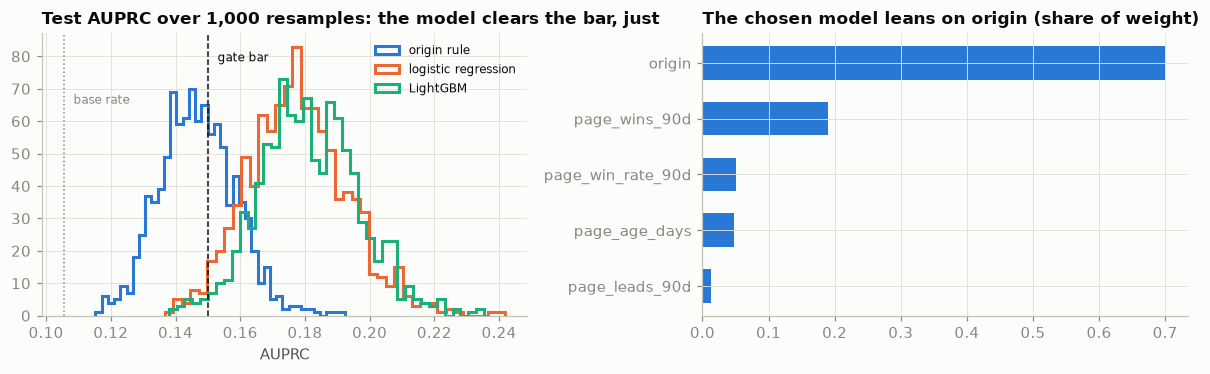

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
ax = axes[0]
for k, c in zip(KINDS, SERIES):
    ax.hist(boots[k], bins=40, histtype="step", lw=2, color=c, label=k)
ax.axvline(GATE_MIN_AUPRC, color=INK, ls="--", lw=1); ax.text(GATE_MIN_AUPRC + 0.003, ax.get_ylim()[1] * 0.9, "gate bar", fontsize=8)
ax.axvline(yt.mean(), color=MUTED, ls=":", lw=1); ax.text(yt.mean() + 0.003, ax.get_ylim()[1] * 0.75, "base rate", color=MUTED, fontsize=8)
ax.set_title("Test AUPRC over 1,000 resamples: the model clears the bar, just"); ax.set_xlabel("AUPRC"); ax.legend(fontsize=8)
ax = axes[1]
if CHOSEN == "LightGBM":
    imp = pd.Series(model.booster_.feature_importance("gain"), index=FEATS)
else:
    imp = pd.Series(np.abs(model.coef_[0]), index=lr_design(X).columns).groupby(lambda c: "origin" if c.startswith("origin") else c).sum()
imp = (imp / imp.sum()).sort_values()
ax.barh(imp.index, imp.values, color=SERIES[0], height=0.6)
ax.set_title("The chosen model leans on origin (share of weight)")
plt.tight_layout()
print("share of the chosen model's weight: " + " · ".join(f"{k} {v:.0%}" for k, v in imp.sort_values(ascending=False).items()))

Logistic regression wins on March (0.199 against 0.171) and is kept, though LightGBM edges it on the test (0.179 against 0.175): switching would be choosing on the holdout. The model beats the origin rule in every resample (+0.031, interval +0.018 to +0.045), but its own AUPRC runs from 0.154 to 0.204. **The CI gate therefore reads the lower bound**: 0.154 against an illustrative bar of 0.15 passes by 0.004, and a slightly worse month would fail it. Origin carries 70 % of the model's weight, the page's recent wins 19 %.

## 4 · The operating point: calls per week against sellers and GMV

*Part B · Given model · package `week_rank` and `closed_at_capacity`; C3 asks you to own calls per week and the planning constants.*

The board buys what 60 calls a week deliver, not AUPRC. Each week the batch ranks that week's leads and the team calls the top *K* (the last, five-day block gets pro-rata calls). Closes become sellers and GMV through two **planning constants** estimated on judgeable deals from Jan – Mar leads, held constant per deal because Trap 3 shows the score does not predict them.

In [11]:
# Planning constants, estimated on deals from the refit window (leads Jan – Mar 2018, seller outcome matured).
# Holding them constant per closed deal is an assumption (checked in Trap 3; varied in task C3).
ref_all = L[trf & (L.closed == 1)]
ref = ref_all[ref_all.seller_matured]                              # deals won late enough are not judged yet
P_ACTIVE = ref.active.mean()
GMV_PER_DEAL = ref.gmv_h.mean()
b_idx = rng.integers(0, len(ref), (N_BOOT, len(ref)))
print(f"planning constants from {len(ref)} of {len(ref_all)} deals (the rest won too late to judge): P(sold within {SELLER_HORIZON_DAYS} d | closed) = {P_ACTIVE:.2f} "
      f"[{np.percentile(ref.active.values[b_idx].mean(1), CI[0]):.2f} – {np.percentile(ref.active.values[b_idx].mean(1), CI[1]):.2f}] · "
      f"{SELLER_HORIZON_DAYS}-day GMV per closed deal R$ {GMV_PER_DEAL:,.0f} "
      f"[{np.percentile(ref.gmv_h.values[b_idx].mean(1), CI[0]):,.0f} – {np.percentile(ref.gmv_h.values[b_idx].mean(1), CI[1]):,.0f}]")

# weekly batches: the queue is re-ranked each week; the last, partial block gets pro-rata calls
T = L[te].copy()
T["score"] = p_te
T["block"] = ((T.first_contact_date - VALID_END).dt.days // 7).values
TEST_DAYS = (TEST_END - VALID_END).days
block_days = np.minimum(7, TEST_DAYS - 7 * np.arange(T.block.max() + 1)).astype(float)
n_weeks = TEST_DAYS / 7
CALL_GRID = np.arange(10, 310, 10)

def week_rank(score, block):
    """Rank of each lead inside its weekly block (0 = best score)."""
    order = np.lexsort((-score, block))
    b_sorted = block[order]
    starts = np.r_[0, np.flatnonzero(np.diff(b_sorted)) + 1]
    rank = np.empty(len(order)); rank[order] = np.arange(len(order)) - np.repeat(starts, np.diff(np.r_[starts, len(order)]))
    return rank

def top_mask(score, block, calls):
    """True for the leads called when the top `calls` leads of each weekly block are called."""
    return week_rank(score, block) < np.round(calls * block_days[block] / 7)

def closed_at_capacity(score, yv, block, calls_grid, idx=None):
    """Closed deals per week at each capacity in `calls_grid`."""
    if idx is not None:
        score, yv, block = score[idx], yv[idx], block[idx]
    rank, frac = week_rank(score, block), block_days[block] / 7
    return np.array([yv[rank < np.round(c * frac)].sum() / n_weeks for c in calls_grid])

yv_, s_, b_ = T.closed.values, T.score.values, T.block.values
op = pd.DataFrame({"calls": CALL_GRID, "model": closed_at_capacity(s_, yv_, b_, CALL_GRID),
                   "origin rule": closed_at_capacity(scores["origin rule"] + rng.random(len(T)) * 1e-9, yv_, b_, CALL_GRID)})
boot_op = np.array([closed_at_capacity(s_, yv_, b_, CALL_GRID, rng.integers(0, len(T), len(T))) for _ in range(N_BOOT)])
op["lo"], op["hi"] = np.percentile(boot_op, CI, axis=0)
leads_pw = len(T) / n_weeks
op["unranked"] = np.minimum(op.calls, leads_pw) * yv_.mean()
op["sellers (model)"] = op.model * P_ACTIVE
op["GMV R$ (model)"] = op.model * GMV_PER_DEAL
op["GMV R$ (unranked)"] = op.unranked * GMV_PER_DEAL
op["marginal closes per 10 calls"] = np.r_[op.model.iloc[0], np.diff(op.model)]
at = op.set_index("calls").loc[CALLS_PER_WEEK]
better = (op["marginal closes per 10 calls"] > 10 * yv_.mean()).values
K_ALL_ABOVE = int(op.calls[np.argmin(better) - 1]) if not better.all() else int(op.calls.max())   # every step up to here beats the base rate
K_ALL_BELOW = int(op.calls[np.flatnonzero(better).max() + 1])                                      # no step from here on does
print(f"{leads_pw:.0f} test leads a week over {n_weeks:.1f} weeks · at {CALLS_PER_WEEK} calls a week: model {at.model:.1f} closed "
      f"[{at.lo:.1f} – {at.hi:.1f}] vs unranked {at.unranked:.1f} and origin rule {at['origin rule']:.1f} → "
      f"{at['sellers (model)']:.1f} sellers and R$ {at['GMV R$ (model)']:,.0f} of {SELLER_HORIZON_DAYS}-day GMV a week "
      f"(unranked: {at.unranked * P_ACTIVE:.1f} sellers, R$ {at['GMV R$ (unranked)']:,.0f})")
print(f"each extra 10 calls beat 10 average leads at every step up to {K_ALL_ABOVE} calls a week, and at no step from {K_ALL_BELOW} on")
op.set_index("calls").loc[[20, 40, 60, 80, 100, 150, 200, 300]].style.format(
    {c: ("{:,.0f}" if c.startswith("GMV") else "{:,.1f}") for c in op.columns if c != "calls"})

planning constants from 397 of 398 deals (the rest won too late to judge): P(sold within 90 d | closed) = 0.40 [0.35 – 0.43] · 90-day GMV per closed deal R$ 576 [289 – 958]


305 test leads a week over 8.7 weeks · at 60 calls a week: model 11.8 closed [10.1 – 13.5] vs unranked 6.3 and origin rule 9.5 → 4.7 sellers and R$ 6,809 of 90-day GMV a week (unranked: 2.5 sellers, R$ 3,645)
each extra 10 calls beat 10 average leads at every step up to 120 calls a week, and at no step from 180 on


,model,origin rule,lo,hi,unranked,sellers (model),GMV R$ (model),GMV R$ (unranked),marginal closes per 10 calls
calls,,,,,,,,,
20,4.1,3.8,3.2,5.3,2.1,1.6,"2,380","1,215",1.6
40,8.0,7.0,6.7,9.4,4.2,3.2,"4,627","2,430",1.8
60,11.8,9.5,10.1,13.5,6.3,4.7,"6,809","3,645",2.0
80,14.8,12.0,13.1,17.0,8.4,5.9,"8,527","4,860",1.5
100,17.9,14.5,15.8,20.2,10.5,7.1,"10,312","6,075",1.1
150,23.2,20.5,20.9,26.2,15.8,9.2,"13,353","9,113",0.7
200,27.3,25.7,24.6,30.4,21.1,10.8,"15,733","12,150",0.3
300,31.6,31.1,28.5,34.4,31.6,12.5,"18,179","18,225",0.2


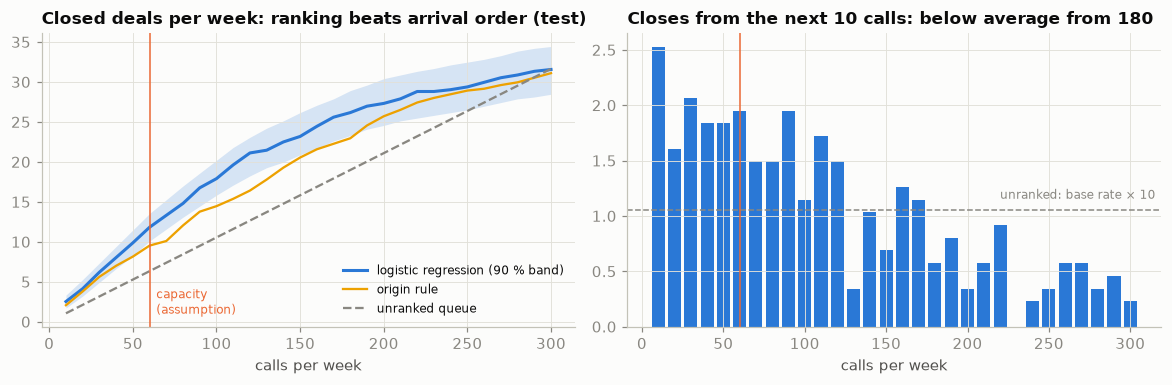

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
ax.fill_between(op.calls, op.lo, op.hi, color=SERIES[0], alpha=0.18, lw=0)
ax.plot(op.calls, op.model, lw=2, color=SERIES[0], label=f"{CHOSEN} (90 % band)")
ax.plot(op.calls, op["origin rule"], lw=1.5, color=SERIES[3], label="origin rule")
ax.plot(op.calls, op.unranked, lw=1.5, ls="--", color=MUTED, label="unranked queue")
ax.axvline(CALLS_PER_WEEK, color=SERIES[1], lw=1); ax.text(CALLS_PER_WEEK + 4, 1, "capacity\n(assumption)", color=SERIES[1], fontsize=8)
ax.set_title("Closed deals per week: ranking beats arrival order (test)"); ax.set_xlabel("calls per week"); ax.legend(fontsize=8)
ax = axes[1]
ax.bar(op.calls, op["marginal closes per 10 calls"], width=8, color=SERIES[0])
ax.axhline(10 * yv_.mean(), color=MUTED, ls="--", lw=1); ax.text(220, 10 * yv_.mean() + 0.1, "unranked: base rate × 10", color=MUTED, fontsize=8)
ax.axvline(CALLS_PER_WEEK, color=SERIES[1], lw=1)
ax.set_title(f"Closes from the next 10 calls: below average from {K_ALL_BELOW}"); ax.set_xlabel("calls per week")
plt.tight_layout()

At 60 calls a week the ranked queue closes 11.8 deals a week (interval 10.1–13.5), against 6.3 for an unranked queue and 9.5 for the origin rule: 4.7 expected sellers and R$ 6.8k of 90-day GMV a week, against 2.5 sellers and R$ 3.6k. The GMV constant is wide (R$ 289–958 per closed deal, half to 1.7 times the estimate). The right-hand chart is the capacity argument: up to 120 calls a week every ten extra calls beat ten average leads (1.05 closes), and from 180 none do. Going from 60 to 100 calls adds 6.1 closes a week, from 100 to 150 another 5.3. Whether that pays needs costs this data lacks (task C3).

## 5 · The traps ⚠

*Part B · Given model · read; C1 turns each trap into a test.*

Four things a careless version would do, each producing a better-looking number.

**Trap 1 — fields written after the call.** The deal file carries nine descriptive fields that sales fills in during or after the consultancy, only for deals it closed. Joined onto the leads with "none" for everyone else, they look like rich features.

**Trap 2 — the landing page and the origin as identifiers.** A page's conversion rate is the obvious feature. Computed over all leads, test months included, it tells the model how April's leads on April's pages turned out.

In [13]:
# Trap 1: post-call fields as features. Missing means "not closed", so the field encodes the label.
XL = X.copy()
for c in ["lead_type", "business_type", "lead_behaviour_profile", "business_segment"]:
    XL[c] = L[c].fillna("none").astype("category")
XL["declared_monthly_revenue"] = L.declared_monthly_revenue.fillna(0)
trap_rows = {}
_, p_leak = fit_predict("LightGBM", trf, te, cols=FEATS + ["lead_type"], X_=XL)
for c in ["has_company", "has_gtin", "average_stock"]:
    XL[c] = L[c].astype(str).fillna("none").astype("category")
XL["declared_product_catalog_size"] = L.declared_product_catalog_size
_, p_rev = fit_predict("LightGBM", trf, te, cols=FEATS + ["declared_monthly_revenue"], X_=XL)
_, p_all9 = fit_predict("LightGBM", trf, te, cols=FEATS + POST_CALL, X_=XL)
trap_rows["Trap 1 · + lead_type (post-call) ⚠"] = average_precision_score(yt, p_leak)
trap_rows["Trap 1 · + declared_monthly_revenue, 0 when missing"] = average_precision_score(yt, p_rev)
trap_rows["Trap 1 · + all nine post-call fields ⚠"] = average_precision_score(yt, p_all9)

# Trap 2: the landing page as an identifier. (a) its conversion rate computed over ALL leads, test months included
all_rate = L[in_window].groupby("landing_page_id").closed.agg(["sum", "size"])
XT = X.copy()
XT["page_rate_all"] = L.landing_page_id.map((all_rate["sum"] + PRIOR_LEADS * BASE_RATE) / (all_rate["size"] + PRIOR_LEADS)).fillna(BASE_RATE)
_, p_te_all = fit_predict("LightGBM", trf, te, cols=["origin", "page_age_days", "page_leads_90d", "weekday", "page_rate_all"], X_=XT)
trap_rows["Trap 2 · page conversion over all leads ⚠"] = average_precision_score(yt, p_te_all)
# (b) the raw page ID as a category, random split vs forward
XT["page_id"] = L.landing_page_id.astype("category")
idx = np.flatnonzero(in_window.values)
i_tr, i_te = train_test_split(idx, test_size=0.3, random_state=SEED, stratify=y.iloc[idx])
m_r = lgb.LGBMClassifier(**LGB_PARAMS).fit(XT.iloc[i_tr][["origin", "page_id"]], y.iloc[i_tr])
ap_rand = average_precision_score(y.iloc[i_te], m_r.predict_proba(XT.iloc[i_te][["origin", "page_id"]])[:, 1])
_, p_id = fit_predict("LightGBM", trf, te, cols=["origin", "page_id"], X_=XT)
seen_pages = set(L.loc[trf, "landing_page_id"])
unseen = ~L.loc[te, "landing_page_id"].isin(seen_pages).values
trap_rows["Trap 2 · raw page ID, random 70/30 split"] = ap_rand
trap_rows["Trap 2 · raw page ID, forward"] = average_precision_score(yt, p_id)
trap_rows[f"honest {CHOSEN}, forward (Section 3)"] = res.loc[CHOSEN, "AUPRC"]
trap_rows["honest LightGBM, forward (the naive rows' learner)"] = res.loc["LightGBM", "AUPRC"]
traps = pd.Series(trap_rows, name="test AUPRC").to_frame()
print(f"base rates: forward test (Apr – May 2018) {yt.mean():.1%} · random 30 % test (Jan – May 2018) {y.iloc[i_te].mean():.1%}")
print(f"test leads on landing pages never seen in Jan – Mar: {unseen.mean():.0%} ({unseen.sum()} leads, conversion {yt[unseen].mean():.1%}); "
      f"honest model on them: AUPRC {average_precision_score(yt[unseen], p_te[unseen]):.3f} (base {yt[unseen].mean():.3f}), "
      f"on known pages {average_precision_score(yt[~unseen], p_te[~unseen]):.3f} (base {yt[~unseen].mean():.3f})")
called = top_mask(p_te, T.block.values, CALLS_PER_WEEK)
nonchannel = L.loc[te, "origin"].isin(["unknown", "(missing)"]).values
print(f"origin 'unknown' or missing: {nonchannel.mean():.0%} of test leads but {nonchannel[called].mean():.0%} of the {CALLS_PER_WEEK}-a-week calls "
      f"(closed rate {yt[nonchannel].mean():.1%} against {yt[~nonchannel].mean():.1%} for named channels)")
traps.style.format("{:.3f}")

base rates: forward test (Apr – May 2018) 10.5% · random 30 % test (Jan – May 2018) 11.3%
test leads on landing pages never seen in Jan – Mar: 23% (613 leads, conversion 7.0%); honest model on them: AUPRC 0.113 (base 0.070), on known pages 0.183 (base 0.116)
origin 'unknown' or missing: 13% of test leads but 48% of the 60-a-week calls (closed rate 18.7% against 9.3% for named channels)


,test AUPRC
Trap 1 · + lead_type (post-call) ⚠,0.915
"Trap 1 · + declared_monthly_revenue, 0 when missing",0.179
Trap 1 · + all nine post-call fields ⚠,0.958
Trap 2 · page conversion over all leads ⚠,0.284
"Trap 2 · raw page ID, random 70/30 split",0.181
"Trap 2 · raw page ID, forward",0.181
"honest logistic regression, forward (Section 3)",0.175
"honest LightGBM, forward (the naive rows' learner)",0.179


`lead_type` alone lifts LightGBM's test AUPRC from 0.179 to 0.915, all nine fields to 0.958. `declared_monthly_revenue` with 0 for missing does nothing (0.179), because 95 % of closed deals declared 0 too: the leak lives in *missingness*. The fix is a feature frame the post-call table cannot reach, not a ban (Section 7 uses these fields legitimately).

The page rate over all leads reaches 0.284, against 0.179 as-of. The raw page ID scores 0.181 on a random split and forward (base rates 11.3 % and 10.5 %), so here the encoding flatters, not the split. Two identifier effects remain. **Pages churn:** 23 % of test leads came from pages unseen in training; they convert at 7.0 %, and on them AUPRC is 0.113 against 0.183 on known pages. **Origin:** leads with origin `unknown` or missing are 13 % of the test but 48 % of the 60 weekly calls, because they close at 18.7 % against 9.3 %. That describes how leads were *recorded*: if marketing fixes its tracking, half the queue's signal moves (task C1).

**Trap 3 — "closed" is not "became a seller".** The CRM counts wins; the business needs sellers. Does the score, which ranks closers, also rank sellers among the test deals whose outcome has matured?

In [14]:
# Trap 3: "closed" is not "became a seller". Test-period deals whose seller outcome has matured.
Tc = T[(T.closed == 1) & T.seller_matured]
auc_active = roc_auc_score(Tc.active, Tc.score)
bi = rng.integers(0, len(Tc), (N_BOOT, len(Tc)))
auc_b = [roc_auc_score(Tc.active.values[i], Tc.score.values[i]) for i in bi if 0 < Tc.active.values[i].sum() < len(i)]
rho = Tc[["score", "gmv_h"]].corr("spearman").iloc[0, 1]
top = T[top_mask(T.score.values, T.block.values, CALLS_PER_WEEK)]
top_m = top[top.closed == 1]
print(f"test deals: {int(T.closed.sum())} closed, {len(Tc)} with a matured seller outcome; {Tc.active.mean():.0%} of those sold within "
      f"{SELLER_HORIZON_DAYS} days, {Tc.good.mean():.0%} sold with reviews ≥ 4")
print(f"does the lead score find sellers among the closed? ROC-AUC {auc_active:.2f} [{np.percentile(auc_b, CI[0]):.2f} – "
      f"{np.percentile(auc_b, CI[1]):.2f}] · Spearman(score, 90-day GMV) {rho:.2f}")
print(f"at {CALLS_PER_WEEK} calls a week the CRM would report {top.closed.sum() / n_weeks:.1f} wins a week; of the matured ones "
      f"{top_m[top_m.seller_matured].active.mean():.0%} sold → ≈ {top.closed.sum() / n_weeks * top_m[top_m.seller_matured].active.mean():.1f} sellers a week")

test deals: 280 closed, 226 with a matured seller outcome; 51% of those sold within 90 days, 39% sold with reviews ≥ 4
does the lead score find sellers among the closed? ROC-AUC 0.51 [0.44 – 0.57] · Spearman(score, 90-day GMV) -0.00
at 60 calls a week the CRM would report 11.8 wins a week; of the matured ones 51% sold → ≈ 6.0 sellers a week


Only half the closed sellers sell: 51 % of the 226 matured test deals sold within 90 days, 39 % with reviews of 4 or more. At 60 calls a week, 11.8 CRM wins a week are about 6.0 sellers. Among closed deals the score does not separate sellers from the rest (ROC-AUC 0.51, interval 0.44–0.57; Spearman with 90-day GMV −0.00): the form tells you who will sign, not who will sell. Report sellers, not wins. The planning constant also moved (0.40 on Jan – Mar deals, 0.51 here), so Section 4's seller count is conservative.

**Trap 4 — survivorship, twice.** The deal table starts on 5 December 2017, so a 2017 lead counts as closed only if it was still open then. The marketplace shows only sellers who sold, so any "per seller" average is an average over survivors.

In [15]:
# Trap 4a: survivorship in the label window. Fit on every lead since Jun 2017, labels as given.
early = L.first_contact_date < WINDOW_START                      # Jun – Dec 2017
trf_all = trf | early
april = (L.loc[te, "month"] == pd.Period("2018-04", "M")).values   # the clean test month (May drifts: Section 6)
Xa = page_history(L, y[trf_all].mean())
s_rows = {}
for name, fit_mask, X_ in [("Jun 2017 – Mar 2018 ⚠", trf_all, Xa), ("Jan – Mar 2018 (honest)", trf, X)]:
    for k in ["origin rule", CHOSEN]:
        _, p = fit_predict(k, fit_mask, te, X_=X_)
        s_rows[(name, k)] = {"leads": int(fit_mask.sum()), "base rate": y[fit_mask].mean(), "test AUPRC": average_precision_score(yt, p),
                             "expected ÷ realised closes (April)": p[april].sum() / yt[april].sum()}
print(f"2017 leads: conversion {y[early].mean():.1%}; median days to close for those that did {dtc[early & won].median():.0f}; "
      f"2018 leads: {y[in_window].mean():.1%} and {dtc[in_window & won].median():.0f} days")
display(pd.DataFrame(s_rows).T.style.format({"leads": "{:,.0f}", "base rate": "{:.1%}", "test AUPRC": "{:.3f}",
                                             "expected ÷ realised closes (April)": "{:.2f}"}))

# Trap 4b: survivorship in seller value. Rank origins by GMV among sellers that sold, per closed deal, and per lead.
o_rows = {}
for o, g in mat.groupby("origin"):
    if len(g) < 40:
        continue
    per_deal = g.gmv_h.values[rng.integers(0, len(g), (N_BOOT, len(g)))].mean(1)
    o_rows[o] = {"matured deals": len(g), "GMV per seller that sold": g.loc[g.active == 1, "gmv_h"].mean(),
                 "sold share": g.active.mean(), "GMV per closed deal": g.gmv_h.mean(),
                 "90 % interval (per deal)": f"{np.percentile(per_deal, CI[0]):,.0f} – {np.percentile(per_deal, CI[1]):,.0f}",
                 "GMV per lead": by_origin.loc[o, "rate"] * g.gmv_h.mean()}
orank = pd.DataFrame(o_rows).T.sort_values("GMV per seller that sold", ascending=False)
orank.style.format({"matured deals": "{:.0f}", "GMV per seller that sold": "R$ {:,.0f}", "GMV per closed deal": "R$ {:,.0f}",
                    "sold share": "{:.0%}", "GMV per lead": "R$ {:,.0f}"})

2017 leads: conversion 0.7%; median days to close for those that did 216; 2018 leads: 11.3% and 12 days


,matured deals,GMV per seller that sold,sold share,GMV per closed deal,90 % interval (per deal),GMV per lead
unknown,154,"R$ 2,015",42%,R$ 837,"248 – 1,768",R$ 162
organic_search,208,"R$ 1,118",39%,R$ 435,247 – 686,R$ 53
paid_search,146,R$ 941,55%,R$ 516,326 – 747,R$ 64
social,55,R$ 532,44%,R$ 232,126 – 355,R$ 12
direct_traffic,49,R$ 408,45%,R$ 183,104 – 265,R$ 24


2017 leads convert at 0.7 % within 90 days, after a median 216 days for those that closed, against 11.3 % and 12 days in 2018. Fitting on every lead since June 2017 barely moves the ranking (AUPRC 0.173 against 0.175; the page features absorb the empty months), but it moves the planning numbers: the origin rule fitted that way expects 0.59 of April's closes, against 0.91 when fitted on 2018. On the seller side, organic search beats paid search on GMV per seller that sold (R$ 1,118 against R$ 941), but per closed deal the order flips (R$ 435 against R$ 516), because 55 % of paid-search deals sold against 39 %. The per-deal intervals overlap widely: this sample cannot rank the two channels.

# Part C — Productionise it

*Sections 6–10: this is your assignment.*

## 6 · After deployment: the channel mix moves, and conversion with it

*Part C · Productionise · what your monitoring plan must catch (C5); reuse `psi` and the expected ÷ realised ratio.*

Freeze the Jan – Mar model and treat April and May as production. The input mix is visible the day a lead arrives, the outcome 90 days later (April's labels are complete on 29 July, May's on 29 August).

In [16]:
def psi(ref_share, cur_share, eps=1e-4):
    r, c = ref_share + eps, cur_share + eps
    return float(np.sum((c - r) * np.log(c / r)))

REF = trf
ref_origin = L[REF].origin.value_counts(normalize=True)
top_pages = L[REF].landing_page_id.value_counts().index[:20]
def page_bucket(s, known):
    return np.where(s.isin(top_pages), s, "any other page")     # new pages land in "any other page"; their share is tracked separately
known_ref = set(L.loc[REF, "landing_page_id"])
ref_page = pd.Series(page_bucket(L.loc[REF, "landing_page_id"], known_ref)).value_counts(normalize=True)
rows = {}
for mth, g in L[L.first_contact_date >= "2017-08-01"].groupby("month"):
    cur_o = g.origin.value_counts(normalize=True).reindex(ref_origin.index.union(g.origin.unique()), fill_value=0)
    cur_p = pd.Series(page_bucket(g.landing_page_id, known_ref)).value_counts(normalize=True)
    keys = ref_page.index.union(cur_p.index)
    rows[mth] = {"leads": len(g), "PSI origin": psi(ref_origin.reindex(cur_o.index, fill_value=0).values, cur_o.values),
                 "PSI landing page": psi(ref_page.reindex(keys, fill_value=0).values, cur_p.reindex(keys, fill_value=0).values),
                 "share on pages new since ref.": (~g.landing_page_id.isin(known_ref)).mean(),
                 "social share": (g.origin == "social").mean(), "closed rate": g.closed.mean()}
drift = pd.DataFrame(rows).T
# frozen model, month by month on the test months (labels mature CLOSE_HORIZON_DAYS after contact)
for mth in [pd.Period("2018-04", "M"), pd.Period("2018-05", "M")]:
    msk = (T.month == mth).values
    drift.loc[mth, "AUPRC (frozen)"] = average_precision_score(T.closed.values[msk], p_te[msk])
    drift.loc[mth, "labels complete on"] = f"{(mth.end_time + pd.Timedelta(days=CLOSE_HORIZON_DAYS)):%d %b %Y}"
display(drift.loc[pd.Period("2017-12", "M"):].style.format({"leads": "{:,.0f}", "PSI origin": "{:.3f}", "PSI landing page": "{:.3f}",
        "share on pages new since ref.": "{:.0%}", "social share": "{:.0%}", "closed rate": "{:.1%}", "AUPRC (frozen)": "{:.3f}"}, na_rep="–"))

# what moved conversion from April to May: the channel mix, or conversion inside each channel?
a, b = L[L.month == pd.Period("2018-04", "M")], L[L.month == pd.Period("2018-05", "M")]
ra, rb = a.groupby("origin").closed.mean(), b.groupby("origin").closed.mean()
sa, sb = a.origin.value_counts(normalize=True), b.origin.value_counts(normalize=True)
keys = sa.index.union(sb.index)
mix_only = (sb.reindex(keys, fill_value=0) * ra.reindex(keys).fillna(a.closed.mean())).sum()
print(f"closed rate April {a.closed.mean():.1%} → May {b.closed.mean():.1%}; May's channel mix at April's rates would give {mix_only:.1%}: "
      f"mix effect {100 * (mix_only - a.closed.mean()):+.1f} pp, change inside channels {100 * (b.closed.mean() - mix_only):+.1f} pp")
print("closed rate inside the biggest channels, April → May: " + " · ".join(
    f"{o} {ra[o]:.1%} → {rb[o]:.1%}" for o in ["organic_search", "paid_search", "social", "unknown"]))

,leads,PSI origin,PSI landing page,share on pages new since ref.,social share,closed rate,AUPRC (frozen),labels complete on
2017-12,200,0.077,0.459,6%,20%,3.0%,–,–
2018-01,"1,141",0.028,0.220,0%,14%,11.3%,–,–
2018-02,"1,028",0.010,0.170,0%,15%,12.5%,–,–
2018-03,"1,174",0.011,0.166,0%,12%,12.0%,–,–
2018-04,"1,352",0.091,1.396,21%,24%,12.6%,0.200,29 Jul 2018
2018-05,"1,303",0.067,1.585,25%,21%,8.4%,0.159,29 Aug 2018


closed rate April 12.6% → May 8.4%; May's channel mix at April's rates would give 12.8%: mix effect +0.2 pp, change inside channels -4.4 pp
closed rate inside the biggest channels, April → May: organic_search 14.6% → 9.6% · paid_search 15.4% → 9.0% · social 4.6% → 3.0% · unknown 20.5% → 16.9%


expected ÷ realised closes by month: Jan 0.90 · Feb 0.99 · Mar 1.10 · Apr 1.02 · May 1.63 · outside the 0.8–1.25 band: May 2018


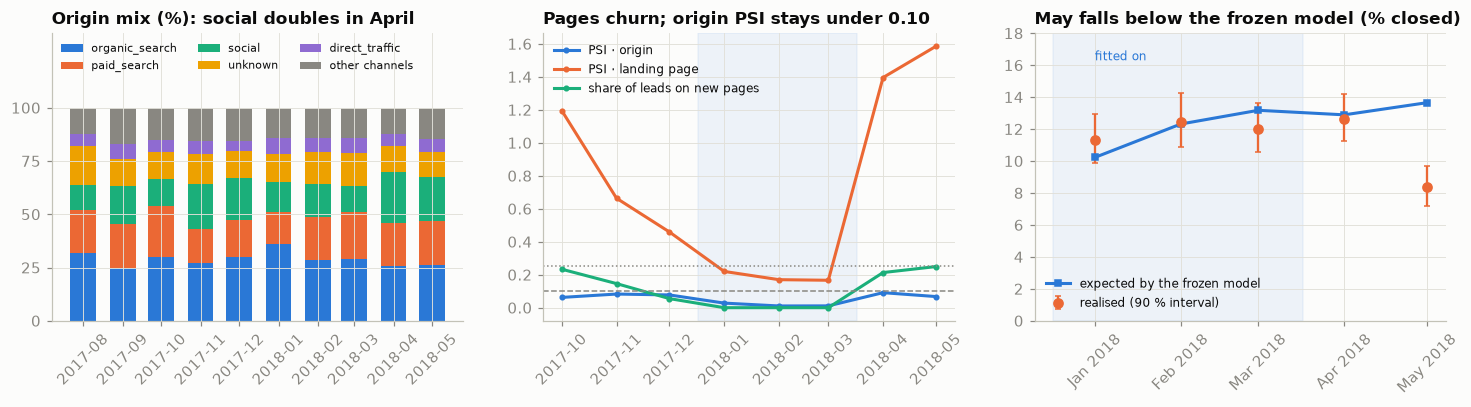

In [17]:
mix = pd.crosstab(L.month, L.origin, normalize="index").loc[pd.Period("2017-08", "M"):]
main = ["organic_search", "paid_search", "social", "unknown", "direct_traffic"]
mix = pd.concat([mix[main], mix.drop(columns=main).sum(axis=1).rename("other channels")], axis=1)
_, p_win = fit_predict(CHOSEN, trf, in_window)                     # the frozen model scores every 2018 month
cal = pd.DataFrame({"month": L.loc[in_window, "month"].values, "p": p_win, "y": y[in_window].values}).groupby("month").agg(
    expected=("p", "mean"), realised=("y", "mean"), n=("y", "size"), k=("y", "sum"))
cal["lo"], cal["hi"] = wilson(cal.k, cal.n)
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))
ax = axes[0]
bottom = np.zeros(len(mix)); colors = SERIES + ["#8f6bd1", MUTED]
for c, col in zip(mix.columns, colors):
    ax.bar(mix.index.to_timestamp(), mix[c] * 100, bottom=bottom, width=20, color=col, label=c); bottom += mix[c].values * 100
ax.set_ylim(0, 135); ax.set_yticks([0, 25, 50, 75, 100])
ax.set_title("Origin mix (%): social doubles in April"); ax.legend(fontsize=7, ncol=3, loc="upper left"); ax.tick_params(axis="x", rotation=45)
ax = axes[1]
dd = drift.loc[pd.Period("2017-10", "M"):]
tt = dd.index.to_timestamp()
ax.plot(tt, dd["PSI origin"], "-o", ms=3, lw=2, color=SERIES[0], label="PSI · origin")
ax.plot(tt, dd["PSI landing page"], "-o", ms=3, lw=2, color=SERIES[1], label="PSI · landing page")
ax.plot(tt, dd["share on pages new since ref."], "-o", ms=3, lw=2, color=SERIES[2], label="share of leads on new pages")
ax.axhline(0.10, color=MUTED, ls="--", lw=1); ax.axhline(0.25, color=MUTED, ls=":", lw=1)
ax.axvspan(WINDOW_START - pd.Timedelta(days=15), VALID_END - pd.Timedelta(days=15), color=SERIES[0], alpha=0.07)
ax.set_title("Pages churn; origin PSI stays under 0.10"); ax.legend(fontsize=8); ax.tick_params(axis="x", rotation=45)
ax = axes[2]
tc = cal.index.to_timestamp()
ax.errorbar(tc, cal.realised * 100, yerr=[(cal.realised - cal.lo) * 100, (cal.hi - cal.realised) * 100], fmt="o", color=SERIES[1], capsize=2, label="realised (90 % interval)")
ax.plot(tc, cal.expected * 100, "-s", ms=4, lw=2, color=SERIES[0], label="expected by the frozen model")
ax.axvspan(tc[0] - pd.Timedelta(days=15), VALID_END - pd.Timedelta(days=15), color=SERIES[0], alpha=0.07)
ax.set_xticks(tc); ax.set_xticklabels([f"{m:%b %Y}" for m in tc])
ax.text(tc[0], 16.3, "fitted on", color=SERIES[0], fontsize=8)
ax.set_ylim(0, 18); ax.set_title("May falls below the frozen model (% closed)"); ax.legend(fontsize=8, loc="lower left"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
ratio = cal.expected / cal.realised
print("expected ÷ realised closes by month: " + " · ".join(f"{m:%b} {r:.2f}" for m, r in ratio.items())
      + f" · outside the {CALIBRATION_BAND[0]}–{CALIBRATION_BAND[1]} band: {', '.join(f'{m:%b %Y}' for m in ratio.index[(ratio < CALIBRATION_BAND[0]) | (ratio > CALIBRATION_BAND[1])]) or 'none'}")

Three signals, read together:

- **Channel mix.** Social doubles, from 12 % of leads in March to 24 % in April, yet the origin PSI stays under the usual 0.10 warning (0.091, 0.067): monitor the shares themselves.
- **Campaigns.** The landing-page PSI jumps to 1.40 and 1.59 as new pages bring 21–25 % of leads; it fires at every campaign launch, so read it against the campaign calendar.
- **Conversion.** The 90-day close rate falls from 12.6 % in April to 8.4 % in May. The mix explains none of it (May's mix at April's rates gives 12.8 %): conversion fell inside every large channel, organic search 14.6 → 9.6 % and paid search 15.4 → 9.0 %. The frozen model expected 1.63 times May's realised closes, and its AUPRC fell from 0.200 to 0.159.

Nothing in the inputs foretold May, and the data cannot say why; it shows only when the labels mature. The retraining trigger must therefore be the calibration ratio, expected ÷ realised closes by contact month, outside an assumed 0.8–1.25 band.

## 7 · A knowledge graph from CRM to marketplace

*Part C · Productionise · package `build_kb`; the ablation and call-prep brief are reference only, extended by E1 and S1.*

The board's second question crosses three systems (`mql_id`, `seller_id`, `order_id`). A small RDF graph makes the link explicit, SHACL validates it and SPARQL answers the competency questions. A curated **crosswalk** joins two vocabularies, the CRM's 33 business segments and the marketplace's Portuguese category codes. It is versioned with the graph, because it is a decision, not a fact.

In [18]:
EX = Namespace("https://example.org/olist-funnel#")
# a curated crosswalk: the CRM's business_segment vocabulary → the marketplace's product categories (versioned with the KB)
SEGMENT_TO_CATEGORIES = {
    "home_decor": ["moveis_decoracao", "casa_conforto", "casa_conforto_2"], "health_beauty": ["beleza_saude"],
    "car_accessories": ["automotivo"], "household_utilities": ["utilidades_domesticas"],
    "construction_tools_house_garden": ["construcao_ferramentas_construcao", "construcao_ferramentas_jardim", "ferramentas_jardim",
                                        "casa_construcao", "construcao_ferramentas_ferramentas", "construcao_ferramentas_iluminacao",
                                        "construcao_ferramentas_seguranca"],
    "audio_video_electronics": ["eletronicos", "audio", "cine_foto", "tablets_impressao_imagem"],
    "computers": ["informatica_acessorios", "pcs", "pc_gamer"], "pet": ["pet_shop"], "food_supplement": ["alimentos", "esporte_lazer"],
    "food_drink": ["alimentos_bebidas", "alimentos", "bebidas"], "sports_leisure": ["esporte_lazer", "fashion_esporte"],
    "bed_bath_table": ["cama_mesa_banho"], "bags_backpacks": ["fashion_bolsas_e_acessorios", "malas_acessorios"], "toys": ["brinquedos"],
    "fashion_accessories": ["fashion_bolsas_e_acessorios", "fashion_calcados", "fashion_roupa_masculina", "fashion_roupa_feminina",
                            "fashion_underwear_e_moda_praia", "fashion_roupa_infanto_juvenil"],
    "home_office_furniture": ["moveis_escritorio", "moveis_sala", "moveis_quarto", "moveis_colchao_e_estofado",
                              "moveis_cozinha_area_de_servico_jantar_e_jardim"],
    "stationery": ["papelaria"], "phone_mobile": ["telefonia", "telefonia_fixa"],
    "small_appliances": ["eletroportateis", "portateis_casa_forno_e_cafe", "portateis_cozinha_e_preparadores_de_alimentos"],
    "handcrafted": ["artes", "artes_e_artesanato"], "baby": ["bebes", "fraldas_higiene"], "music_instruments": ["instrumentos_musicais"],
    "books": ["livros_tecnicos", "livros_interesse_geral", "livros_importados"], "watches": ["relogios_presentes"],
    "jewerly": ["relogios_presentes"], "home_appliances": ["eletrodomesticos", "eletrodomesticos_2"],
    "party": ["artigos_de_festas", "artigos_de_natal"], "gifts": ["relogios_presentes", "cool_stuff"],
    "air_conditioning": ["climatizacao"], "perfume": ["perfumaria"], "games_consoles": ["consoles_games", "pc_gamer"],
}   # "other" and "religious" are deliberately unmapped: SHACL should say so

def iri(kind, key):
    return EX[f"{kind}/{key[:12]}"]

def build_kb(L: pd.DataFrame, mk: pd.DataFrame) -> Graph:
    g = Graph(); g.bind("ex", EX)
    for r in L.itertuples(index=False):
        lead = iri("lead", r.mql_id)
        g.add((lead, RDF.type, EX.Lead))
        g.add((lead, EX.firstContact, Literal(r.first_contact_date.date(), datatype=XSD.date)))
        g.add((lead, EX.origin, EX[f"origin/{r.origin.strip('()')}"]))
        g.add((lead, EX.landingPage, iri("page", r.landing_page_id)))
        if isinstance(r.seller_id, str):
            s = iri("seller", r.seller_id)
            g.add((lead, EX.becameSeller, s)); g.add((s, RDF.type, EX.Seller))
            g.add((s, EX.wonDate, Literal(r.won_date.date(), datatype=XSD.date)))
            g.add((s, EX.leadContact, Literal(r.first_contact_date.date(), datatype=XSD.date)))   # copied for a same-node check
            if isinstance(r.business_segment, str):
                seg = EX[f"segment/{r.business_segment}"]
                g.add((s, EX.segment, seg)); g.add((seg, RDF.type, EX.Segment))
    for seg, cats in SEGMENT_TO_CATEGORIES.items():
        for c in cats:
            g.add((EX[f"segment/{seg}"], EX.sellsInCategory, EX[f"category/{c}"]))
    o = mk.drop_duplicates(["order_id", "seller_id"])
    for r in o.itertuples(index=False):
        order = iri("order", r.order_id)
        g.add((order, RDF.type, EX.Order)); g.add((order, EX.soldBy, iri("seller", r.seller_id)))
        g.add((order, EX.purchased, Literal(r.purchased.date(), datatype=XSD.date)))
        if not np.isnan(r.review_score):
            g.add((order, EX.reviewScore, Literal(float(r.review_score), datatype=XSD.decimal)))
    for r in mk.groupby(["order_id", "seller_id"]).price.sum().reset_index().itertuples(index=False):
        g.add((iri("order", r.order_id), EX.value, Literal(round(float(r.price), 2), datatype=XSD.decimal)))
    return g

t0 = time.time()
kb = build_kb(L, mk)
print(f"crosswalk: {L.business_segment.nunique()} CRM segments in the deals, {len(SEGMENT_TO_CATEGORIES)} mapped to "
      f"{len({c for v in SEGMENT_TO_CATEGORIES.values() for c in v})} of the marketplace's {items.category.nunique()} categories")
print(f"knowledge graph: {len(kb):,} triples · {len(set(kb.subjects(RDF.type, EX.Lead))):,} leads · "
      f"{len(set(kb.subjects(RDF.type, EX.Seller)))} sellers · {len(set(kb.subjects(RDF.type, EX.Order))):,} orders · built in {time.time()-t0:.1f}s")

crosswalk: 33 CRM segments in the deals, 31 mapped to 63 of the marketplace's 73 categories
knowledge graph: 58,818 triples · 8,000 leads · 842 sellers · 4,504 orders · built in 1.7s


In [19]:
SHAPES = """
@prefix sh: <http://www.w3.org/ns/shacl#> . @prefix ex: <https://example.org/olist-funnel#> . @prefix xsd: <http://www.w3.org/2001/XMLSchema#> .
ex:LeadShape a sh:NodeShape ; sh:targetClass ex:Lead ;
  sh:property [ sh:path ex:firstContact ; sh:minCount 1 ; sh:maxCount 1 ; sh:datatype xsd:date ] ;
  sh:property [ sh:path ex:landingPage ; sh:minCount 1 ; sh:maxCount 1 ] ;
  sh:property [ sh:path ex:becameSeller ; sh:maxCount 1 ] .
ex:SellerShape a sh:NodeShape ; sh:targetClass ex:Seller ;
  sh:property [ sh:path ex:wonDate ; sh:minCount 1 ; sh:maxCount 1 ] ;
  sh:property [ sh:path [ sh:inversePath ex:becameSeller ] ; sh:minCount 1 ; sh:maxCount 1 ; sh:message "a seller comes from exactly one lead" ] ;
  sh:property [ sh:path ex:segment ; sh:minCount 1 ; sh:message "closed deal without a business segment" ] ;
  sh:property [ sh:path ex:leadContact ; sh:lessThanOrEquals ex:wonDate ; sh:message "deal won before the lead's first contact" ] .
ex:SegmentShape a sh:NodeShape ; sh:targetClass ex:Segment ;
  sh:property [ sh:path ex:sellsInCategory ; sh:minCount 1 ; sh:message "CRM segment not linked to any marketplace category" ] .
ex:OrderShape a sh:NodeShape ; sh:targetClass ex:Order ;
  sh:property [ sh:path ex:soldBy ; sh:minCount 1 ; sh:class ex:Seller ] ;
  sh:property [ sh:path ex:reviewScore ; sh:maxCount 1 ; sh:minInclusive 1 ; sh:maxInclusive 5 ] .
"""
t0 = time.time()
conforms, report_g, _ = pyshacl.validate(kb, shacl_graph=Graph().parse(data=SHAPES, format="turtle"), inference="none")
SH = Namespace("http://www.w3.org/ns/shacl#")
viol = pd.DataFrame([{"message": str(report_g.value(r, SH.resultMessage)), "focus": str(report_g.value(r, SH.focusNode)).split("#")[-1]}
                     for r in report_g.subjects(RDF.type, SH.ValidationResult)])
print(f"SHACL conforms: {conforms} · {len(viol)} violations in {time.time()-t0:.1f}s")
display(viol.groupby("message").agg(n=("focus", "size"), focus=("focus", lambda f: ", ".join(sorted(f)[:3]))))

SHACL conforms: False · 4 violations in 2.1s


,n,focus
message,,
CRM segment not linked to any marketplace category,2,"segment/other, segment/religious"
closed deal without a business segment,1,seller/ec5b3cd9d6bf
deal won before the lead's first contact,1,seller/5e063e85d44b


In [20]:
Q = {
 "CQ1 · Which closed sellers never sold anything on the marketplace?": """
   SELECT (COUNT(DISTINCT ?s) AS ?sellers) WHERE { ?s a ex:Seller . FILTER NOT EXISTS { ?o ex:soldBy ?s } }""",
 "CQ2 · By origin: leads, sellers, and sellers that sold": """
   SELECT ?origin (COUNT(DISTINCT ?l) AS ?leads) (COUNT(DISTINCT ?s) AS ?sellers) (COUNT(DISTINCT ?sold) AS ?sold) WHERE {
     ?l a ex:Lead ; ex:origin ?origin . OPTIONAL { ?l ex:becameSeller ?s . OPTIONAL { ?o ex:soldBy ?s . BIND(?s AS ?sold) } } }
   GROUP BY ?origin ORDER BY DESC(?leads) LIMIT 5""",
 "CQ3 · For the lead at the top of this week's queue: what became of earlier sellers from its landing page?": """
   SELECT (COUNT(DISTINCT ?s) AS ?sellers) (COUNT(DISTINCT ?sold) AS ?sold_before_today) (AVG(?score) AS ?avg_review) WHERE {
     ?l ex:landingPage <PAGE> ; ex:becameSeller ?s . ?s ex:wonDate ?w . FILTER(?w < "TODAY"^^xsd:date)
     OPTIONAL { ?o ex:soldBy ?s ; ex:purchased ?d . FILTER(?d < "TODAY"^^xsd:date) BIND(?s AS ?sold) OPTIONAL { ?o ex:reviewScore ?score } } }""",
}
# the lead at the top of the last full test week's queue (it reappears in the call-prep pack below)
last = T[T.block == T.block.max() - 1].sort_values("score", ascending=False).iloc[0]
cq = {}
for name, q in Q.items():
    t0 = time.time()
    rows = kb.query(q.replace("PAGE", str(iri("page", last.landing_page_id))).replace("TODAY", f"{last.first_contact_date:%Y-%m-%d}"),
                    initNs={"ex": EX, "xsd": XSD})
    val = lambda v: (v.toPython() if isinstance(v.toPython(), int) else round(float(v.toPython()), 2)) if isinstance(v, Literal) \
        else (str(v).split("/")[-1] if v is not None else None)
    out = pd.DataFrame([[val(v) for v in r] for r in rows], columns=[str(v) for v in rows.vars])
    cq[name[:3]] = out
    print(f"{name}  ({time.time()-t0:.1f}s)"); display(out)

CQ1 · Which closed sellers never sold anything on the marketplace?  (0.2s)


,sellers
0,463


CQ2 · By origin: leads, sellers, and sellers that sold  (1.4s)


,origin,leads,sellers,sold
0,organic_search,2296,271,112
1,paid_search,1586,195,101
2,social,1350,75,31
3,unknown,1099,179,81
4,direct_traffic,499,56,31


CQ3 · For the lead at the top of this week's queue: what became of earlier sellers from its landing page?  (0.4s)


,sellers,sold_before_today,avg_review
0,137,43,4.36


SHACL earns its keep: two CRM segments (`other`, `religious`) map to no marketplace category, one closed deal has no segment, and one deal is dated before its lead's first contact. CQ1 finds the 463 sellers never seen selling (50 won after the extract ends); CQ2 shows social's weakness end to end (1,350 leads, 75 sellers, 31 sold); CQ3 feeds the call-prep brief.

**The ablation.** Does marketplace-category context help? Before the call it cannot: the segment is unknown and the biggest landing pages are not category pages (printed below). So the ablation sits right after the call: which new sellers need onboarding help to start selling? Target: sold within 90 days of the win; train on deals won Dec 2017 – Mar 2018, test on April – 1 June 2018. Context, through the crosswalk and as of the won date: six 90-day statistics of the segment's marketplace categories (orders, sellers, growth, reviews, price).

In [21]:
# Ablation: does marketplace-category context (through the KB crosswalk) help predict which closed deals become sellers?
# Decision point: right after the call, when the segment is known. Context is computed as of the won date.
cat_orders = items[VALID_ORDER].drop_duplicates(["order_id", "category"])[["category", "order_id", "seller_id", "purchased", "review_score", "review_date", "price"]]
seg_frames = {}
for seg, cats in SEGMENT_TO_CATEGORIES.items():
    f = cat_orders[cat_orders.category.isin(cats)].drop_duplicates("order_id").sort_values("purchased")
    seg_frames[seg] = (f.purchased.values, f.seller_id.values, f.review_score.values, f.review_date.values, f.price.values)

def category_context(seg, t):
    if seg not in seg_frames:
        return dict(ctx_orders_90d=np.nan, ctx_sellers_90d=np.nan, ctx_orders_per_seller=np.nan, ctx_growth=np.nan, ctx_review=np.nan, ctx_price=np.nan)
    ts, sel, rev, rdate, price = seg_frames[seg]
    t = np.datetime64(t); a0, a1 = np.searchsorted(ts, [t - np.timedelta64(90, "D"), t]); b0 = np.searchsorted(ts, t - np.timedelta64(180, "D"))
    n_now, n_before, sellers = a1 - a0, a0 - b0, len(np.unique(sel[a0:a1]))
    rv_ok = rev[a0:a1][(rdate[a0:a1] < t) & ~np.isnan(rev[a0:a1])]   # only reviews already written at decision time
    return dict(ctx_orders_90d=np.log1p(n_now), ctx_sellers_90d=np.log1p(sellers), ctx_orders_per_seller=n_now / max(sellers, 1),
                ctx_growth=np.log((n_now + 10) / (n_before + 10)), ctx_review=rv_ok.mean() if len(rv_ok) else np.nan,
                ctx_price=np.log1p(np.median(price[a0:a1])) if n_now else np.nan)

big = L[won].landing_page_id.value_counts().index[:2]
print("the two biggest landing pages are not category pages: top segment = " + " · ".join(
    f"{L[won & (L.landing_page_id == pg)].business_segment.value_counts(normalize=True).iloc[0]:.0%} of {int((won & (L.landing_page_id == pg)).sum())} deals"
    for pg in big))
D = mat.copy()
D = D.join(pd.DataFrame([category_context(s, t) for s, t in zip(D.business_segment, D.won_date)], index=D.index))
D = D.join(X[["page_age_days", "page_leads_90d", "page_win_rate_90d"]])
D["origin"] = D.origin.astype("category")
CRM_FIELDS = ["business_segment", "lead_type", "business_type", "lead_behaviour_profile"]
for c in CRM_FIELDS:
    D[c] = D[c].fillna("none").astype("category")
FORM = ["origin", "page_age_days", "page_leads_90d", "page_win_rate_90d"]
CTX = ["ctx_orders_90d", "ctx_sellers_90d", "ctx_orders_per_seller", "ctx_growth", "ctx_review", "ctx_price"]
dtr, dte = D.won_date < VALID_END, D.won_date >= VALID_END
LGB_SMALL = dict(LGB_PARAMS, n_estimators=150, num_leaves=4, min_child_samples=20, min_data_per_group=10)
abl, abl_boot = {}, {}
for name, cols in [("lead form only", FORM), ("lead form + KB category context", FORM + CTX),
                   ("lead form + CRM fields from the call", FORM + CRM_FIELDS),
                   ("lead form + CRM fields + KB category context", FORM + CRM_FIELDS + CTX)]:
    m = lgb.LGBMClassifier(**LGB_SMALL).fit(D.loc[dtr, cols], D.active[dtr])
    p = m.predict_proba(D.loc[dte, cols])[:, 1]
    a_, lo, hi, bs = boot_ap(D.active[dte], p)
    abl[name] = {"AUPRC": a_, "90 % interval": f"{lo:.3f} – {hi:.3f}", "ROC-AUC": roc_auc_score(D.active[dte], p)}
    abl_boot[name] = bs
ab = pd.DataFrame(abl).T
d_ctx = abl_boot["lead form + CRM fields + KB category context"] - abl_boot["lead form + CRM fields from the call"]
d_crm = abl_boot["lead form + CRM fields from the call"] - abl_boot["lead form only"]
print(f"deals: train (won Dec 2017 – Mar 2018) {dtr.sum()}, {D.active[dtr].mean():.0%} sold · test (won Apr – {D.won_date.max():%d %b} 2018) "
      f"{dte.sum()}, {D.active[dte].mean():.0%} sold")
print(f"paired differences in AUPRC: CRM fields {np.mean(d_crm):+.3f} [{np.percentile(d_crm, CI[0]):+.3f}, {np.percentile(d_crm, CI[1]):+.3f}] · "
      f"KB context on top {np.mean(d_ctx):+.3f} [{np.percentile(d_ctx, CI[0]):+.3f}, {np.percentile(d_ctx, CI[1]):+.3f}]")
ab.style.format({"AUPRC": "{:.3f}", "ROC-AUC": "{:.3f}"})

the two biggest landing pages are not category pages: top segment = 15% of 174 deals · 12% of 171 deals


deals: train (won Dec 2017 – Mar 2018) 336, 41% sold · test (won Apr – 01 Jun 2018) 331, 46% sold
paired differences in AUPRC: CRM fields +0.095 [+0.045, +0.149] · KB context on top -0.053 [-0.096, -0.012]


,AUPRC,90 % interval,ROC-AUC
lead form only,0.499,0.440 – 0.567,0.560
lead form + KB category context,0.505,0.445 – 0.575,0.583
lead form + CRM fields from the call,0.594,0.528 – 0.665,0.657
lead form + CRM fields + KB category context,0.540,0.482 – 0.612,0.635


The fields the rep records on the call help: +0.095 AUPRC (interval +0.045 to +0.149). Category context does not: alone it is within noise of the lead form (0.505 against 0.499), and on top of the CRM fields it costs 0.053 (−0.096 to −0.012), six more features for 336 training deals. At this sample size the graph earns its place by joining and validating three systems, not by adding accuracy. `lead_type` leaked in Trap 1 and is legitimate here: leakage depends on the decision time, not the column.

**A call-prep brief, without an LLM.** Task S1's brief rests on a **context pack** (score, CQ3's page history, matured outcomes, caveats), here for the top lead of the last full test week. An LLM may phrase the template better; it may not add facts.

In [22]:
# A call-prep context pack for that lead: everything an LLM brief may use, and nothing else
earlier = L[(L.landing_page_id == last.landing_page_id) & L.won_date.notna() & (L.won_date < last.first_contact_date)]
earlier_m = earlier[earlier.won_date + pd.Timedelta(days=SELLER_HORIZON_DAYS) <= last.first_contact_date]
kb_ans = cq["CQ3"].iloc[0]
pack = {
    "lead": {"ref": last.mql_id[:8], "first_contact": f"{last.first_contact_date:%Y-%m-%d}", "origin": last.origin, "page": last.landing_page_id[:8]},
    "score": {"p_close_90d": round(float(last.score), 2), "rank_this_week": 1, "base_rate": round(float(yt.mean()), 3), "model": CHOSEN},
    "page_history_kb": {"earlier_sellers": int(kb_ans.sellers), "sold_before_today": int(kb_ans.sold_before_today),
                        "avg_review": round(float(kb_ans.avg_review), 2), "leads_last_90d": int(X.loc[last.name, "page_leads_90d"]),
                        "wins_last_90d": int(X.loc[last.name, "page_wins_90d"])},
    "page_history_matured": {"deals_old_enough": len(earlier_m), "sold_within_90d": int(earlier_m.active.sum()),
                             "top_segments": list(earlier.business_segment.value_counts().head(3).index)},
    "caveats": ["a ranking, not a promise", "origin not recorded for this lead" if last.origin in ("unknown", "(missing)") else "",
                "segment unknown until the call"],
}
for k, v in pack.items():
    print(f"{k:22s} {json.dumps(v, ensure_ascii=False)}")
via = "with no recorded origin" if last.origin in ("unknown", "(missing)") else f"via {last.origin}"
brief = (f"Lead {pack['lead']['ref']} arrived {via} on {pack['lead']['first_contact']}; its 90-day close probability is "
         f"{last.score:.0%} against a base rate of {yt.mean():.0%}. Its landing page has produced {int(kb_ans.sellers)} sellers, "
         f"{int(kb_ans.sold_before_today)} of whom have sold (average review {float(kb_ans.avg_review):.1f}); of the {len(earlier_m)} "
         f"won early enough to judge, {int(earlier_m.active.sum())} sold within {SELLER_HORIZON_DAYS} days. Typical segments: "
         f"{', '.join(pack['page_history_matured']['top_segments'])}. Ask about catalogue and stock: closing is not the goal, selling is.")
print("\ntemplate brief (deterministic, no LLM):\n" + brief)

lead                   {"ref": "b51d0cee", "first_contact": "2018-05-21", "origin": "(missing)", "page": "22c29808"}
score                  {"p_close_90d": 0.55, "rank_this_week": 1, "base_rate": 0.105, "model": "logistic regression"}
page_history_kb        {"earlier_sellers": 137, "sold_before_today": 43, "avg_review": 4.36, "leads_last_90d": 426, "wins_last_90d": 106}
page_history_matured   {"deals_old_enough": 31, "sold_within_90d": 12, "top_segments": ["home_decor", "car_accessories", "construction_tools_house_garden"]}
caveats                ["a ranking, not a promise", "origin not recorded for this lead", "segment unknown until the call"]

template brief (deterministic, no LLM):
Lead b51d0cee arrived with no recorded origin on 2018-05-21; its 90-day close probability is 55% against a base rate of 11%. Its landing page has produced 137 sellers, 43 of whom have sold (average review 4.4); of the 31 won early enough to judge, 12 sold within 90 days. Typical segments: home_decor, car_

## 8 · The module spine for this project

*Part C · Productionise · the targets your system must meet, with this notebook's numbers.*

The card's plan, updated with what this notebook measured.

| Spine | In this project |
|---|---|
| Package and container (S02–S03) | `src/lead_scoring/` (`features`, `train`, `score`, `kb`); a weekly batch writes ranked scores to a CRM table (≈ 300 leads a week); `GET /leads/{id}` returns score and context pack. |
| Monitoring (S04) | Now: channel shares (social 12 % → 24 %), origin PSI (≤ 0.09), new-page share (21–25 %), job runtime. After 90 days: expected ÷ realised closes by contact month (May 1.63), AUPRC by month, share of deals that sold. |
| CI/CD gate (S05) | Frozen Apr – May 2018 holdout (2,655 leads, 280 closed, SHA-256 fingerprint): 5th-percentile AUPRC ≥ 0.15, an illustrative bar (0.154, PASS) and paired gain over the origin rule > 0 (lower bound +0.018). |
| MLflow tracking and registry (S06) | Windows, both horizons, seed, intervals, calls per week, planning constants (0.40, R$ 576), outcome-definition and crosswalk versions, holdout fingerprint; `champion` and `challenger` aliases. |
| Offline / online training and serving | Offline weekly batch; online explanation in the CRM. Retrain monthly on matured labels, early if expected ÷ realised leaves 0.8–1.25 (assumption). |
| Data and model drift | Social doubling; 23 % of test leads on new pages; a May fall in conversion inside every channel (12.6 % → 8.4 %) invisible in the inputs; P(sold \| closed) 0.40 → 0.51. |
| Knowledge base and context (S07–S09) | 58,818 triples (lead → seller → order → review; segment → category); four SHACL violations. Ablation on "sold within 90 days": CRM fields +0.095 AUPRC, KB category context −0.053. |
| GenAI and context engineering (S10–S11) | Call-prep brief from a context pack (score, CQ3 page history, caveats); versioned prompt; golden set; no fact outside the pack. |
| Governance | CC BY-NC-SA 4.0 (non-commercial, share alike); employee IDs dropped, review text never loaded; sole traders' data can be personal data (GDPR); intervals, not leaderboards. |

## 9 · Student tasks

*Part C · Productionise · your assignment.*

This is an individual assignment: you pick one task from the catalogue, claimed first come, first served, so no other student works on it. **The model is given:** you package, evaluate, deploy and monitor this notebook's model; you do not design, tune or replace it. Where a task re-runs training (removing a leaking input, a retraining policy, a knowledge-base ablation), run the notebook's own training code with only its inputs or configuration changed. Work in your own repository, not in this notebook. Promote code into the `src/` package layout from Session 02, keep the notebook as a thin client, and record each design decision as an ADR in `docs/decisions/`. **Required:** all *Core* tasks (C1–C5), all *Extension* tasks (E1–E4) and Stretch **S1**, the GenAI task (Sessions 10–11). No API key is provided: run it on a local open-weight model, with a free hosted tier as an optional comparison, under the data rule for this task in [`docs/llm-access.md`](docs/llm-access.md). The other Stretch tasks are optional and count only towards the top band. The mark rewards the quality of each task, not the number done; the criteria are in `docs/task-rubric.md`.

### Core

- **C1 — Find and fix every trap.** Post-call fields in a frame no feature code can reach; `tests/test_features.py` fails if a page feature uses a lead or win from the contact day on; train only where the deal table is complete; find out what `unknown` origins mean and how much of the queue rides on them.
- **C2 — Reproduce and freeze the given model.** Package the notebook's own data loading, features, training and scoring unchanged, retrain from a fresh clone with `SEED`, and show that your pipeline reproduces the numbers listed under *How this notebook is organised* within a tolerance you state. Add a data contract on the raw inputs (schema and value ranges, for example with pandera) and record any difference from the notebook in an ADR. No new features, learners or tuning.
- **C3 — Own the operating point.** Vary `CALLS_PER_WEEK` (20–300), both horizons and the planning constants; add a cost per call and a take rate (assumptions) to find where the marginal call stops paying; write the ADR the sales lead signs.
- **C4 — Package, container, gate.** `src/lead_scoring/` with the weekly batch and `GET /leads/{id}`, a slim container, and `make ci` running the two-condition gate on the fingerprinted Apr – May 2018 holdout (Sessions 02, 03, 05).
- **C5 — Register, document, monitor.** MLflow runs with intervals and fingerprints; `champion` and `challenger` aliases; a model card (sampled leads, truncated deal table, non-channel origins, closed ≠ sold, the May fall); a monitoring plan with channel shares and the expected ÷ realised trigger under a 90-day label delay (Sessions 04, 06).

### Extension

- **E1 — The knowledge-base ablation.** Extend the graph from competency questions, version the crosswalk, run SHACL in CI, and measure with and without KB context at both decision points (before the call: the page's seller history; after it: category context), with paired intervals (Sessions 07–09).
- **E2 — Governance: reps and sellers.** Would allocating leads by rep performance (the dropped `sdr_id`, `sr_id`) bring the system into Annex III, point 4 of the AI Act (employment)? What is the GDPR basis for scoring sole traders, and what does CC BY-NC-SA let you ship?
- **E3 — The label clock.** Show how long the 90-day delay leaves a May-style fall undetected, and which signal available earlier (closes per week, origin mix) would have fired first; add it to the monitoring plan.
- **E4 — What the 90-day label hides.** Using the data as it is (no new model), count the closed deals that sell after 90 days or never, by origin, and argue in an ADR whether the label definition should change and who would decide.

### Stretch

- **S1 — The call-prep brief.** Generate it with an LLM from the context pack only (versioned prompt, structured output); a golden set of 30 leads whose facts must be reproduced exactly; a prompt-injection test; cost per brief (Sessions 10–11).
- **S2 — Online and streaming serving.** Score each lead as the form is submitted, with page history kept by a streaming job; compare cost and freshness per 1,000 leads with the weekly batch.
- **S3 — Value beyond 90 days, as a reporting question.** Report realised GMV per seller cohort over the longest window the data allows, with an interval, and say whether the board should keep ranking on closes.

## 10 · Hand-in checklist

*Part C · Productionise · tick every box before you submit.*

- [ ] Repository in the Session 02 layout; fresh-clone test passes; `data/` not committed; employee IDs never loaded
- [ ] `README.md` states windows, splits, horizons and how to obtain both datasets (CC BY-NC-SA 4.0)
- [ ] Forward evaluation with bootstrap intervals; traps removed; as-of and post-call tests in the suite
- [ ] Operating point (calls per week → deals, sellers, GMV) in a signed ADR
- [ ] CI with the lower-bound gate; registered model, model card, monitoring plan with the calibration trigger
- [ ] Knowledge graph with SHACL shapes, the crosswalk and the ablation
- [ ] One-page recommendation for the sales lead
- [ ] Required tasks done: C1–C5, E1–E4 and S1
- [ ] GenAI task runs on a local model; any hosted run follows the data rule and logs provider, model and cost
- [ ] Reflective diary entry: what you chose, rejected, and what evidence would change your mind

---

### Appendix — environment and references

- Python ≥ 3.11; `pandas`, `pyarrow`, `scikit-learn`, `lightgbm`, `matplotlib`, `rdflib`, `pyshacl`, `kagglehub` (pinned in `requirements.txt`).
- Olist (2018). *Marketing Funnel by Olist* and *Brazilian E-Commerce Public Dataset by Olist*. Kaggle, CC BY-NC-SA 4.0.
- Efron, B., Tibshirani, R. J. (1993). *An Introduction to the Bootstrap.* Chapman & Hall.
- Kaufman, S., Rosset, S., Perlich, C. (2012). *Leakage in Data Mining: Formulation, Detection, and Avoidance.* ACM TKDD.
- Huyen, C. (2022). *Designing Machine Learning Systems*, Ch. 5 (leakage), Ch. 8 (distribution shifts).
- W3C (2017). *Shapes Constraint Language (SHACL).*

In [23]:
print(f"pandas {pd.__version__} · numpy {np.__version__} · lightgbm {lgb.__version__} · scikit-learn {sklearn.__version__} · "
      f"rdflib {rdflib.__version__} · pyshacl {pyshacl.__version__}")
print(f"notebook finished · total wall time {time.time()-T_START:.0f}s")

pandas 3.1.0 · numpy 2.5.4 · lightgbm 4.7.0 · scikit-learn 1.9.1 · rdflib 7.6.0 · pyshacl 0.40.1
notebook finished · total wall time 20s
